# A complete tour of Petrophys

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/complete_tour.ipynb)

This notebook walks one real North Sea well from raw LAS file to per-formation
net pay, and then goes wider: four wells side by side, core calibration, cutoff
and parameter sensitivity, specialist data and a gallery of the library's
plots. Every section runs on data bundled with the package, so the notebook
works offline and every number you see is computed in the cell above it.

Each step is one or two lines: `pp.read` loads a well, `pp.interpret` runs the
whole interpretation on a copy of it, `pp.plot` draws it, and the result
reports itself as tables (`result.summary`, `result.formation_summary`,
`result.to_dataframe`). To see what a method does, change its setting and
compare the results.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

By the end of this tour you will be able to:

- Load a LAS well with formation tops and lithology intervals, and inspect its
  curves, units and header parameters.
- Interpret it in one call, read the warnings, the trace and the plot, and
  change any setting.
- Compare clay-volume, porosity, saturation and permeability methods by
  changing one setting at a time.
- Summarize results per formation, per zone and per depth window, and roll
  them up to in-place volumes.
- Interpret several wells at once, calibrate logs against core, and test how
  sensitive net pay is to cutoffs and parameters.
- Pick the right plot for each question.

### Prerequisites

Install the package with the tutorial extra (`python -m pip install -e ".[tutorials]"`
from the repository root); section 18 also uses the `ml` extra. The
[Quickstart](../docs/quickstart.md) is a gentler first contact; this tour assumes you
know what a well log is but nothing about the library.

## Why this matters

A petrophysical answer such as "30 m of net pay" is the end of a long chain:
curve names and units, bad-hole screening, clay volume, porosity, formation-water
resistivity at the right temperature, a saturation model, cutoffs, and the depth
window you add it up over. A mistake anywhere in the chain changes the answer.
`pp.interpret` runs the whole chain in one call and records every link: which
method it chose, which values it assumed and which steps it skipped. This tour
shows where to find each link and how to change it, so that when a number
surprises you, you know where to look.

### How this tour relates to the lessons

Each section here is a summary. The lesson in the right-hand column covers the
same ground in depth, with the theory and more exercises.

| Tour section | Lesson that goes deeper |
|---|---|
| 1. Loading and inspecting a LAS file | [01 - Loading and inspecting data](part_a_foundations/01_loading_and_inspecting_data.ipynb) |
| 2. The interpretation in one call | [10 - Dynamic workflow glass box](part_b_advanced/10_dynamic_workflow_glass_box.ipynb) |
| 3. Curve standardization and QC | [02 - QA/QC and standardization](part_a_foundations/02_qaqc_and_standardization.ipynb) |
| 4. Lithology and formation tops | [05 - Lithology and mineral solver](part_a_foundations/05_lithology_and_mineral_solver.ipynb), [11 - Formation and interval analysis](part_b_advanced/11_formation_and_interval_analysis.ipynb) |
| 5. Clay volume | [03 - Clay volume](part_a_foundations/03_clay_volume.ipynb) |
| 6. Porosity | [04 - Porosity](part_a_foundations/04_porosity.ipynb) |
| 7. Water saturation | [06 - Formation water and environment](part_a_foundations/06_formation_water_and_environment.ipynb), [07 - Water saturation](part_a_foundations/07_water_saturation.ipynb) |
| 8. Permeability | [08 - Permeability](part_a_foundations/08_permeability.ipynb) |
| 9. Net pay | [09 - Reservoir quality and net pay](part_a_foundations/09_reservoir_quality_and_net_pay.ipynb) |
| 10. Formation and zone summaries | [11 - Formation and interval analysis](part_b_advanced/11_formation_and_interval_analysis.ipynb) |
| 11. Reading the trace | [10 - Dynamic workflow glass box](part_b_advanced/10_dynamic_workflow_glass_box.ipynb) |
| 12. Multi-well comparison | [18 - Multi-well field study](part_b_advanced/18_multiwell_field_study.ipynb) |
| 13. Rock quality and flow units | [09 - Reservoir quality and net pay](part_a_foundations/09_reservoir_quality_and_net_pay.ipynb) |
| 14. In-place volumes | [11 - Formation and interval analysis](part_b_advanced/11_formation_and_interval_analysis.ipynb) |
| 15. Exporting results | [10 - Dynamic workflow glass box](part_b_advanced/10_dynamic_workflow_glass_box.ipynb), [19 - LLM context generation](part_b_advanced/19_llm_context_generation.ipynb) |
| 16. Core data and log-core calibration | [12 - Core calibration and digital core](part_b_advanced/12_core_calibration_and_digital_core.ipynb) |
| 17. Sensitivity analysis | [10 - Dynamic workflow glass box](part_b_advanced/10_dynamic_workflow_glass_box.ipynb) |
| 18. Specialist data | [13 - ML curve imputation](part_b_advanced/13_ml_curve_imputation.ipynb), [14 - NMR](part_b_advanced/14_nmr_petrophysics.ipynb), [15 - Saturation height](part_b_advanced/15_capillary_pressure_saturation_height.ipynb), [16 - Borehole images](part_b_advanced/16_borehole_image_fmi.ipynb), [20 - MCP server](part_b_advanced/20_mcp_server.ipynb), [21 - Custom workflows](part_b_advanced/21_custom_workflows.ipynb) |
| 19. Visualization gallery | [17 - Visualization masterclass](part_b_advanced/17_visualization_masterclass.ipynb) |

The case studies in `examples/case_studies/` apply the same tools to complete
problems; CS1 (30/6-5) and CS5 (saturation-model sensitivity) are the closest
to this tour. They read 30/6-5 without the tops and lithology files and use a
porosity cutoff of 0.08, so their Brent Group net pay (24 to 26 m) differs from
the 22.4 m of this tour; section 4 shows what the lithology source alone does.

### Data and working assumptions

Everything comes from the bundled samples (`pp.list_samples()`):

- **Main well: GeoLink 30/6-5** (Oseberg Øst, Norwegian North Sea, depths in
  metres). Its reservoir is the **Brent Group, 2841-2958 m** (`BRENT GP.` in the
  bundled tops): the Ness Fm. (2841-2865 m) over the Etive Fm.
  (2865-2958 m). The Dunlin Group lies below, the Statfjord Group deeper still (the
  bundled tops keep the picks' label `Statfjord Fm.`).
  Formation tops: `pp.sample("formations_30_6-5")`; lithology intervals:
  `pp.sample("lithology_30_6-5")`; core plugs are stored in the LAS as the
  curves `PHIC` (porosity), `KH_CORE` (permeability), `GDEN` (grain density)
  and `SWC` (water saturation).
- **Formation water for 30/6-5: Rw = 0.070 ohm.m measured at 230 degF**, with
  Archie constants a = 0.80, m = n = 2 (the operator values used in lessons 07-09).
  The bundled LAS header records the same value (`RW = 0.07` ohm.m with
  `RWT = 230` degF). The temperature matters: an Rw without its temperature is
  taken at the median formation temperature, which changes saturation strongly.
- **Cutoffs:** VCL < 0.40, PHIE > 0.10 and Sw < 0.60. The library's clastic
  defaults are the same except PHIE > 0.08.
- **Other wells:** 25/5-1, 15/9-14 and 16/7-1 in the multi-well section, and
  25/5-1 again for a second core data set; section 12 says where each Rw comes
  from. Section 18 adds COSTA, Daydream-1 and 25/5-1 specialist data.

Reservoir numbers are reported for the Brent Group window or per formation, never as
whole-well totals. Section 9 shows why: shallow, poorly compacted sediments can
pass porosity and saturation cutoffs too.

The setup cell keeps these choices in two names used throughout: `SETTINGS`
for the interpretation and `BRENT` for the reservoir window. It also prints
warnings as one line each, without the library file they come from, and shows
long table cells in full.

In [2]:
import warnings
import pandas as pd
import petrophys as pp

warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"
pd.set_option("display.max_colwidth", None)

SETTINGS = dict(rw=0.070, rw_meas_temp="230 degF",      # Rw 0.070 ohm.m at 230 degF
                a=0.8, m=2, n=2,                   # operator Archie constants
                vcl_cutoff=0.40, phie_cutoff=0.10, sw_cutoff=0.60)
BRENT = dict(top=2841, bottom=2958)                # Brent Group: Ness + Etive, m

---
## 1. Loading and inspecting a LAS file

`pp.read` reads a LAS (or DLIS, CSV, TSV) file and returns a `Well`: the
library's central object, holding depth-indexed curves, the LAS header and any
parameters. `formations=` and `lithology=` attach the formation tops and
lithology intervals, which plots label and the interpretation uses. Reading
never calculates anything; curves keep the names and units found in the file.

In [3]:
well = pp.read(pp.sample("30_6-5"),
               formations=pp.sample("formations_30_6-5"),
               lithology=pp.sample("lithology_30_6-5"))
print(well.info())

Well: 30/6-5
UWI: 30/6-5
Field: OSEBERG ØST
Depth range: 176.61 - 3556.08 m
Step: 0.1524 m
Number of curves: 20
Number of samples: 22176

Curves:
  LITHOLOGY_GEOLINK: _, 10732 valid
  CALI: in, 22084 valid
  DRHO: g/cm3, 17421 valid
  NPHI: m3/m3, 17421 valid
  RHOB: g/cm3, 22171 valid
  PEF: b/e, 2569 valid
  GR: gAPI, 22176 valid
  DTC: us/ft, 22081 valid
  DTE: us/ft, 22081 valid
  RDEP: ohm.m, 22171 valid
  SP: mV, 22169 valid
  RSHA: ohm.m, 22079 valid
  RMED: ohm.m, 22171 valid
  BS: in, 22176 valid
  PHIC: v/v, 200 valid
  GDEN: g/c3, 200 valid
  KH_CORE: mD, 198 valid
  KV_CORE: mD, 198 valid
  SWC: frac, 74 valid
  SOC: frac, 44 valid


In [4]:
well.get_parameter("RW"), well.get_parameter("RWT"), well.get_parameter("BHT")

(0.07, 230.0, 126.0)

The header carries `RW = 0.07` ohm.m together with the temperature it was
measured at (`RWT = 230` degF), the operator value we use throughout, and a
maximum bottom-hole temperature `BHT` in degC, from which the interpretation
builds its temperature profile.

`to_dataframe()` gives a pandas view with a `DEPTH` column, and `depth_slice`
cuts a window. The top of the well has no density-neutron data, so we look at
the first rows of the Brent Group.

In [5]:
well.depth_slice(**BRENT).to_dataframe().head()

,DEPTH,LITHOLOGY_GEOLINK,CALI,DRHO,NPHI,RHOB,PEF,GR,DTC,DTE,...,SP,RSHA,RMED,BS,PHIC,GDEN,KH_CORE,KV_CORE,SWC,SOC
0,2841.01929,7.0,9.578,-0.007,0.28411,2.59649,3.610,130.875,77.06660,73.31969,...,60.6676,9.211,8.563,8.5,NaN,NaN,NaN,NaN,NaN,NaN
1,2841.17188,7.0,9.234,-0.001,0.27285,2.60078,4.206,105.750,75.14113,71.37544,...,60.4176,8.703,9.445,8.5,NaN,NaN,NaN,NaN,NaN,NaN
2,2841.32422,2.0,9.086,0.014,0.24820,2.57707,4.800,81.438,75.53908,71.67464,...,60.2921,5.980,8.602,8.5,NaN,NaN,NaN,NaN,NaN,NaN
3,2841.47656,2.0,9.070,0.009,0.22200,2.53539,5.084,65.375,78.63948,74.68752,...,59.7327,7.730,6.016,8.5,NaN,NaN,NaN,NaN,NaN,NaN
4,2841.62891,2.0,9.070,0.005,0.21171,2.50126,4.852,58.625,82.61350,78.80270,...,60.7915,6.461,4.117,8.5,NaN,NaN,NaN,NaN,NaN,NaN


Wells in the same data set rarely have identical curve suites. A second GeoLink
well, 25/5-1, adds spectral gamma (`THOR`, `URAN`) and drilling curves, and its
header records its own Rw with a reference temperature.

In [6]:
other = pp.read(pp.sample("25_5-1"))
sorted(set(other.curves) - set(well.curves)), other.get_parameter("RW"), other.get_parameter("RWT")

(['MUDWEIGHT', 'ROP', 'THOR', 'URAN'], 0.047, 200.0)

`pp.plot` builds the tracks from whatever curves are present, labels the
attached formations and draws the core plugs as points. `top` and `bottom`
choose the window; here, the Brent Group with the shale above and below it.

The core saturation curve `SWC` is stored in percent although the LAS labels it
`frac`. For display, `pp.plot` divides it (and the oil saturation `SOC`) by
100 on a copy and raises a `UserWarning` for each, printed above the figure;
the curve on the well stays in percent.

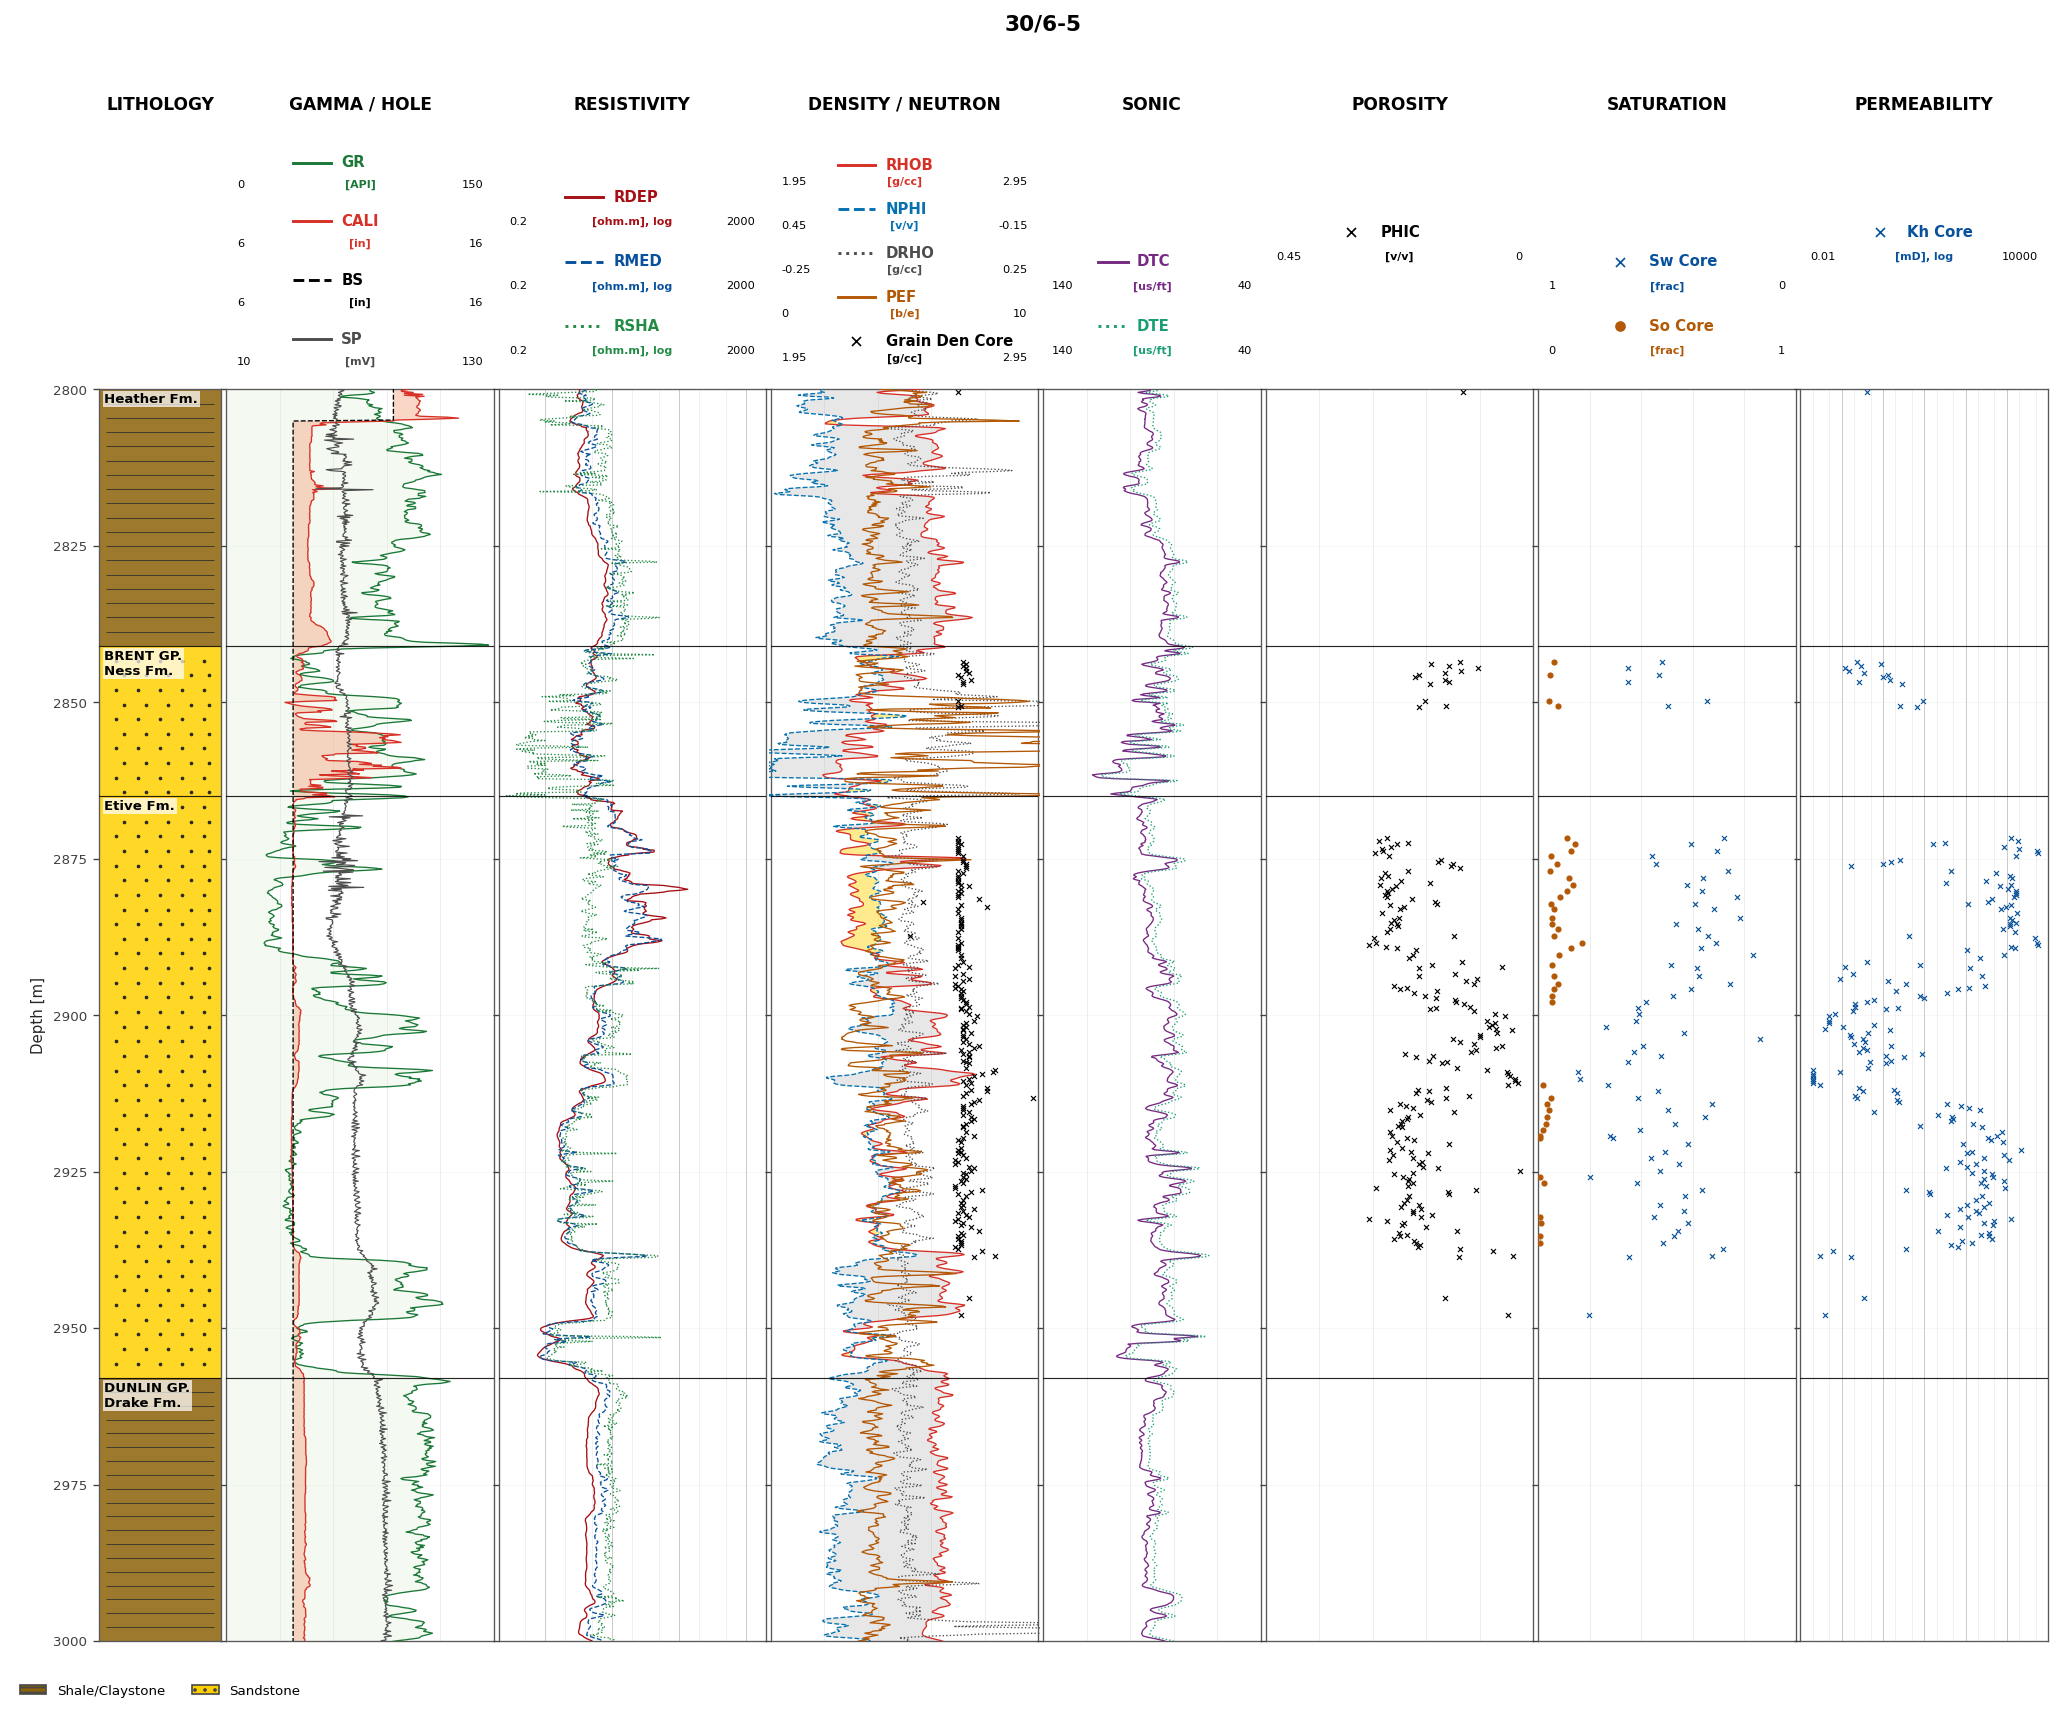

In [7]:
pp.plot(well, top=2800, bottom=3000).show()

Read the plot as a petrophysicist would: the clean, low-GR Etive sand and the
heterolithic Ness (sand, silt and coal) between the Heather and Drake shales, high deep
resistivity in the upper Etive (hydrocarbons) over lower resistivity below
(water), and the density-neutron crossover of light-fluid sand.

In [8]:
# pp.interpret and the core functions convert SWC and SOC from percent for their
# own use and warn each time. The note is explained above, so hide only that
# message; every other warning still shows.
warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")

---
## 2. The interpretation in one call

`pp.interpret` runs the whole chain: it checks which curves and parameters are
available, runs every step it can (standardization, temperature, bad hole,
clay volume, porosity, lithology, core correction, Rw, saturation,
permeability, rock quality, net pay, ...), and records why it skipped any step.
It works on a **copy** of the well and returns a result whose `well` holds the
calculated curves.

Settings are passed as keywords, here the `SETTINGS` of the setup cell. Every
setting is a field of `pp.DynamicWorkflowConfig`, documented there; a setting
left out is read from the LAS header or derived from the data, and the trace
says which.

In [9]:
result = pp.interpret(well, **SETTINGS)
result.status

'interpreted'

In [10]:
for warning in result.warnings:
    print("-", warning)

- Held readings, one value repeated exactly over ten samples or more: RHOB 1.8 over 180.42-242.752 m (411 samples), RSHA 7.012 over 3537.94-3555.32 m (116 samples), RHOB 1.9602 over 1461.19-1468.66 m (51 samples), GR 187.5 over 3548.77-3556.08 m (50 samples), RHOB 1.899 over 529.416-536.274 m (47 samples) and 28 more. A tool that stopped reading, or a log padded to a depth, holds its last value while the other logs change; check these against the other logs before using them.
- Marl uses the limestone matrix and carbonate cutoff family. This is a routing convention, not a calibrated marl model; check clay correction and supply project-specific cutoffs.
- External lithology: unmapped labels [], 30 uncovered samples. Labels/gaps are preserved; unclassified samples use configured calculation fallbacks, not inferred rock labels.
- lithology: PEF set aside: in 96% of 259 clean porous samples the apparent matrix density is quartz-like (< 2.67 g/cm3) but the apparent matrix U calcite-like (> 

The warnings are the first thing to read. Here: several logs hold one reading
over long runs, padded or stopped readings at the top and base of the logs;
the `marl` interval of the lithology file is routed to the carbonate cutoffs by convention; a few samples
fall outside the lithology file; the PEF reads like barite-weighted mud, so the
mineral solver leaves it out; the bad-hole flag removes net pay; and a sliver of pay at 2805 m, just below
the casing shoe, has a shale gamma ray but a neutron-density point that reads clean.
Section 3 looks at the bad-hole flag.

The deliverable display is `pp.plot(result, template="petrophysics")`:
lithology, GR/VCL/hole, resistivity, density-neutron-sonic, porosity,
saturation, permeability and the net-pay flags, with core points and the
attached formation tops.

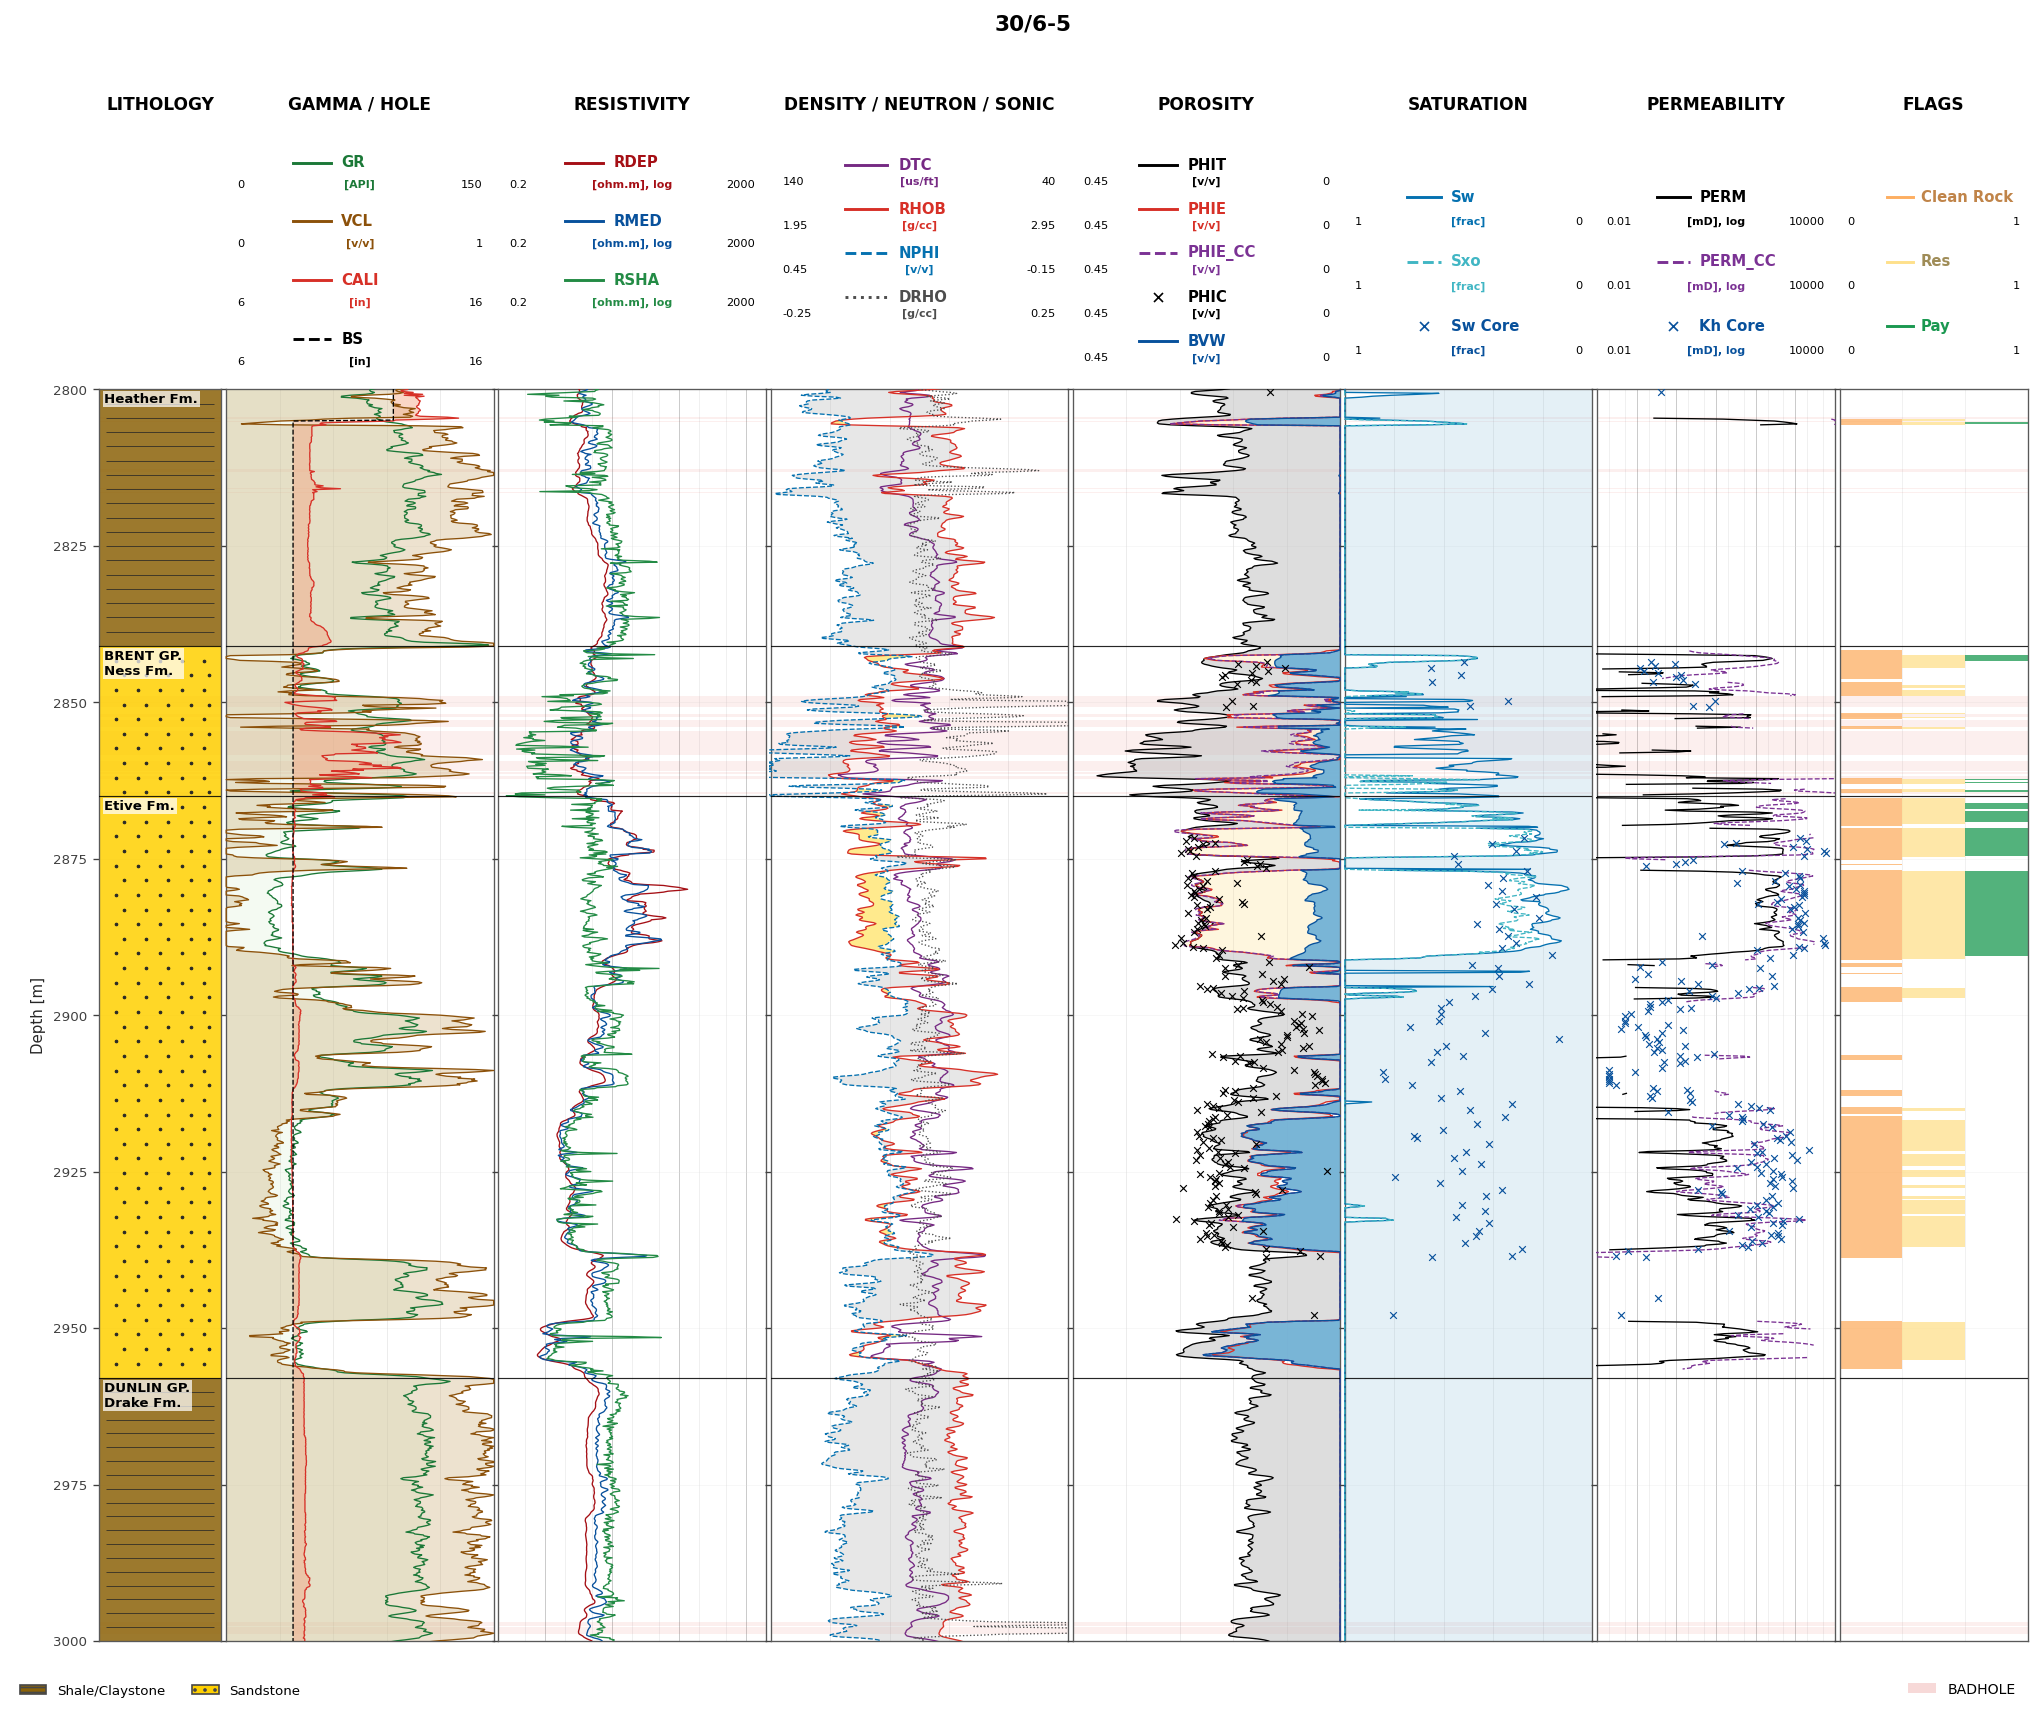

In [11]:
pp.plot(result, template="petrophysics", top=2800, bottom=3000).show()

In the Brent Group the porosity curves run through the core points (crosses)
in the clean Etive sand, Sw falls to about 0.2 in its upper part, and the
flags track shows net rock, net reservoir and net pay, with pay concentrated
in the upper Etive. The pink bands mark bad hole, mostly in the Ness Fm.

The permeability track shows the empirical `PERM` and the core-calibrated
`PERM_CC` against the plugs (section 8).

---
## 3. Curve standardization and quality control

Before any calculation, curves need standard mnemonics and units, implausible
values need screening, and depths in bad hole need flagging. `pp.interpret`
does all three first. `result.step(name)` returns the record of one step: its
`method`, `parameters` and `decisions`, the reasoning in words.

In [12]:
result.step("normalization").decisions + result.step("bad_hole").decisions

['Curve units, null values and plausible ranges standardized before interpretation',
 'No standard curve names needed adding: the logs use them already',
 '12631 bad-hole samples flagged out of 22176']

`CurveStandardizer().report(well)` previews the mapping without changing
anything: which curves it recognises and which units it converts. The GeoLink
files already use standard names, so it mostly confirms units; `SWC` and `SOC`
go from `frac` to `v/v`, with the percent-to-fraction step noted in section 1.

In [13]:
from petrophys.preprocessing import CurveStandardizer, detect_washout

pd.DataFrame(CurveStandardizer().report(well)["unit_conversions"])

,curve,from_unit,to_unit
0,NPHI,m3/m3,v/v
1,GR,gAPI,API
2,SWC,frac,v/v
3,SOC,frac,v/v


**Bad-hole flags** mark depths where pad tools (density, PEF) may read the mud
instead of the rock: caliper well above bit size (washout), large hole, low
density, a high density correction `DRHO`, or implausible PEF. `detect_washout`
returns the flags and their statistics over the whole well.

In [14]:
pd.Series(detect_washout(well).statistics).round(1)

washout_count               7841.0
washout_percent               35.4
washout_thickness           1195.0
large_hole_count            5108.0
large_hole_percent            23.0
large_hole_thickness         778.5
low_density_count          11046.0
low_density_percent           49.8
low_density_thickness       1683.4
pef_exclusion_count          134.0
pef_exclusion_percent          0.6
pef_exclusion_thickness       20.4
bad_hole_count             12631.0
bad_hole_percent              57.0
bad_hole_thickness          1925.0
dtype: float64

Over the whole well the combined flag covers 57 % of the samples (about
1925 m), almost all in the large, soft-sediment top hole. The `GAMMA / HOLE`
track shows the caliper against the bit size, and the pink bands the combined
flag that the interpretation stores as `BAD_HOLE`. Below 3060 m, in the Drake
Fm. shale, the caliper opens to almost 16 in (bit size 8.5 in) and `DRHO` swings widely; in
the Cook Fm. sand below, the caliper still reads 2-3.5 in over bit size. The
density there is suspect, so the flagged samples stay out of net reservoir and
net pay: the Cook Fm. has net rock but no net reservoir in section 10.

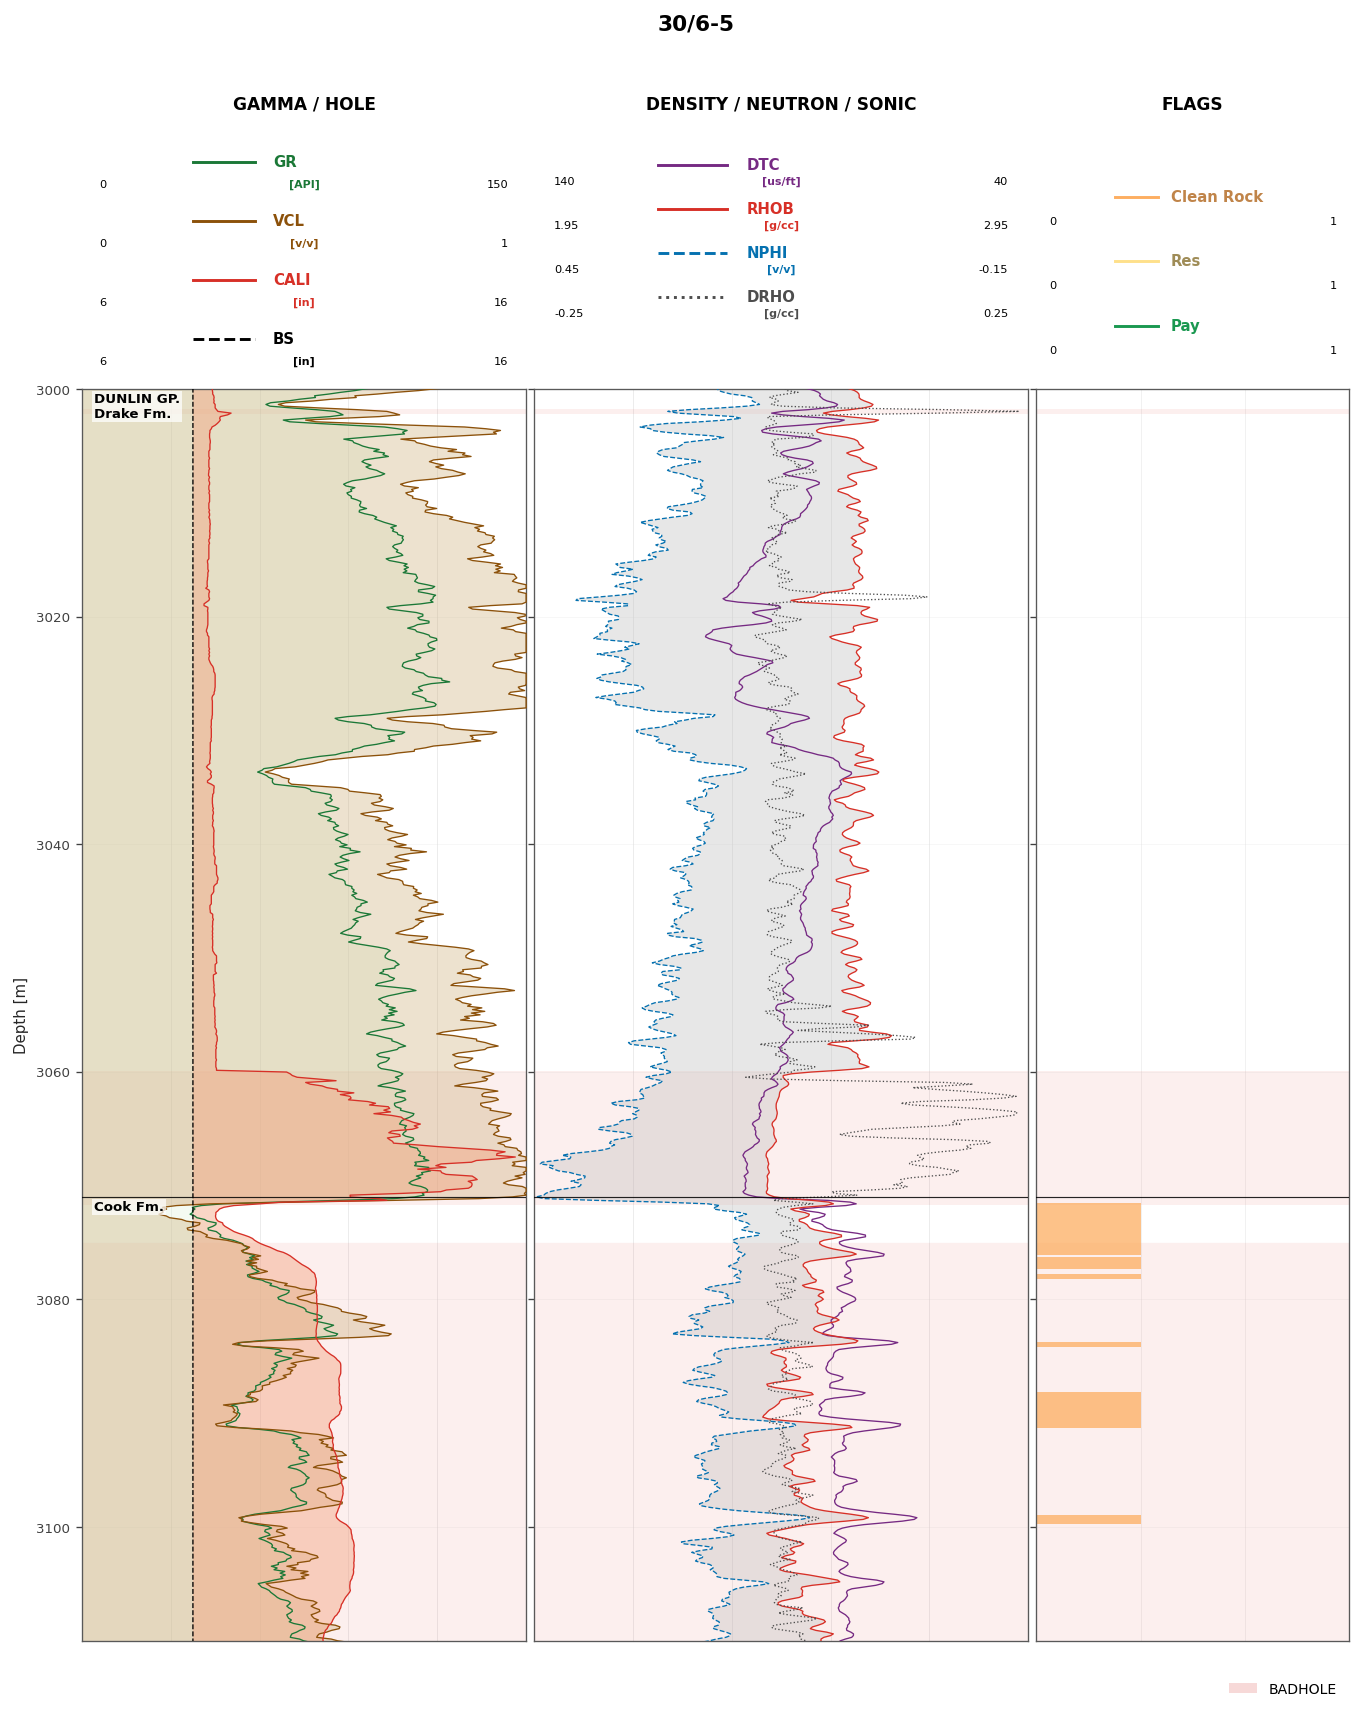

In [15]:
pp.plot(result, template="petrophysics", top=3000, bottom=3110,
        tracks=["GAMMA / HOLE", "DENSITY / NEUTRON / SONIC", "FLAGS"]).show()

**Value-range QC** replaces physically implausible values with NaN. In 30/6-5
it masks 301 `DRHO` samples and a few `PEF`, `GR` and `DTC` samples, small
enough that the trace records them (section 11) without a warning; larger
removals are warned, as for 15/9-14 in section 12. The `bad_hole` setting
changes the flag thresholds (`bad_hole={"cali": 2.0}`), and
`skip_steps=["bad_hole"]` keeps the flagged pay.

---
## 4. Lithology and formation tops

Formation tops and lithology intervals are optional context: plots label
them, interval summaries need them, and the interpretation uses lithology to
choose matrix properties, cutoff families and which samples cannot be pay.
`pp.read_formations` loads tops as a validated table. The bundled 30/6-5 tops
mix **groups** and the **formations** within them, so some rows overlap (the
`BRENT GP.` row covers both Ness and Etive); the `rank` column says which is
which.

In [16]:
pp.read_formations(pp.sample("formations_30_6-5"), well=well)

,formation_name,top_depth,bottom_depth,lithology,rank,parent,depth_unit
0,NORDLAND GP.,181.0,726.0,Shale,group,,m
1,Utsira Fm.,726.0,879.0,Sandstone,formation,,m
2,HORDALAND GP.,879.0,1908.0,Shale,group,,m
3,ROGALAND GP.,1908.0,2203.0,Shale,group,,m
4,Balder Fm.,1908.0,2023.0,Shale,formation,ROGALAND GP.,m
5,Sele Fm.,2023.0,2123.0,Shale,formation,ROGALAND GP.,m
6,Lista Fm.,2123.0,2203.0,Shale,formation,ROGALAND GP.,m
7,SHETLAND GP.,2203.0,2408.0,Marl,group,,m
8,CROMER KNOLL GP.,2408.0,2452.0,Marl,group,,m
9,VIKING GP.,2452.0,2841.0,Shale,group,,m


The well also carries a vendor lithology curve, `LITHOLOGY_GEOLINK`, with one
numeric code per sample; `pp.plot` names the codes in its lithology track.
Read without the interval file, the well shows the vendor codes; compare them
with the coarse interval file in the plot of section 2.

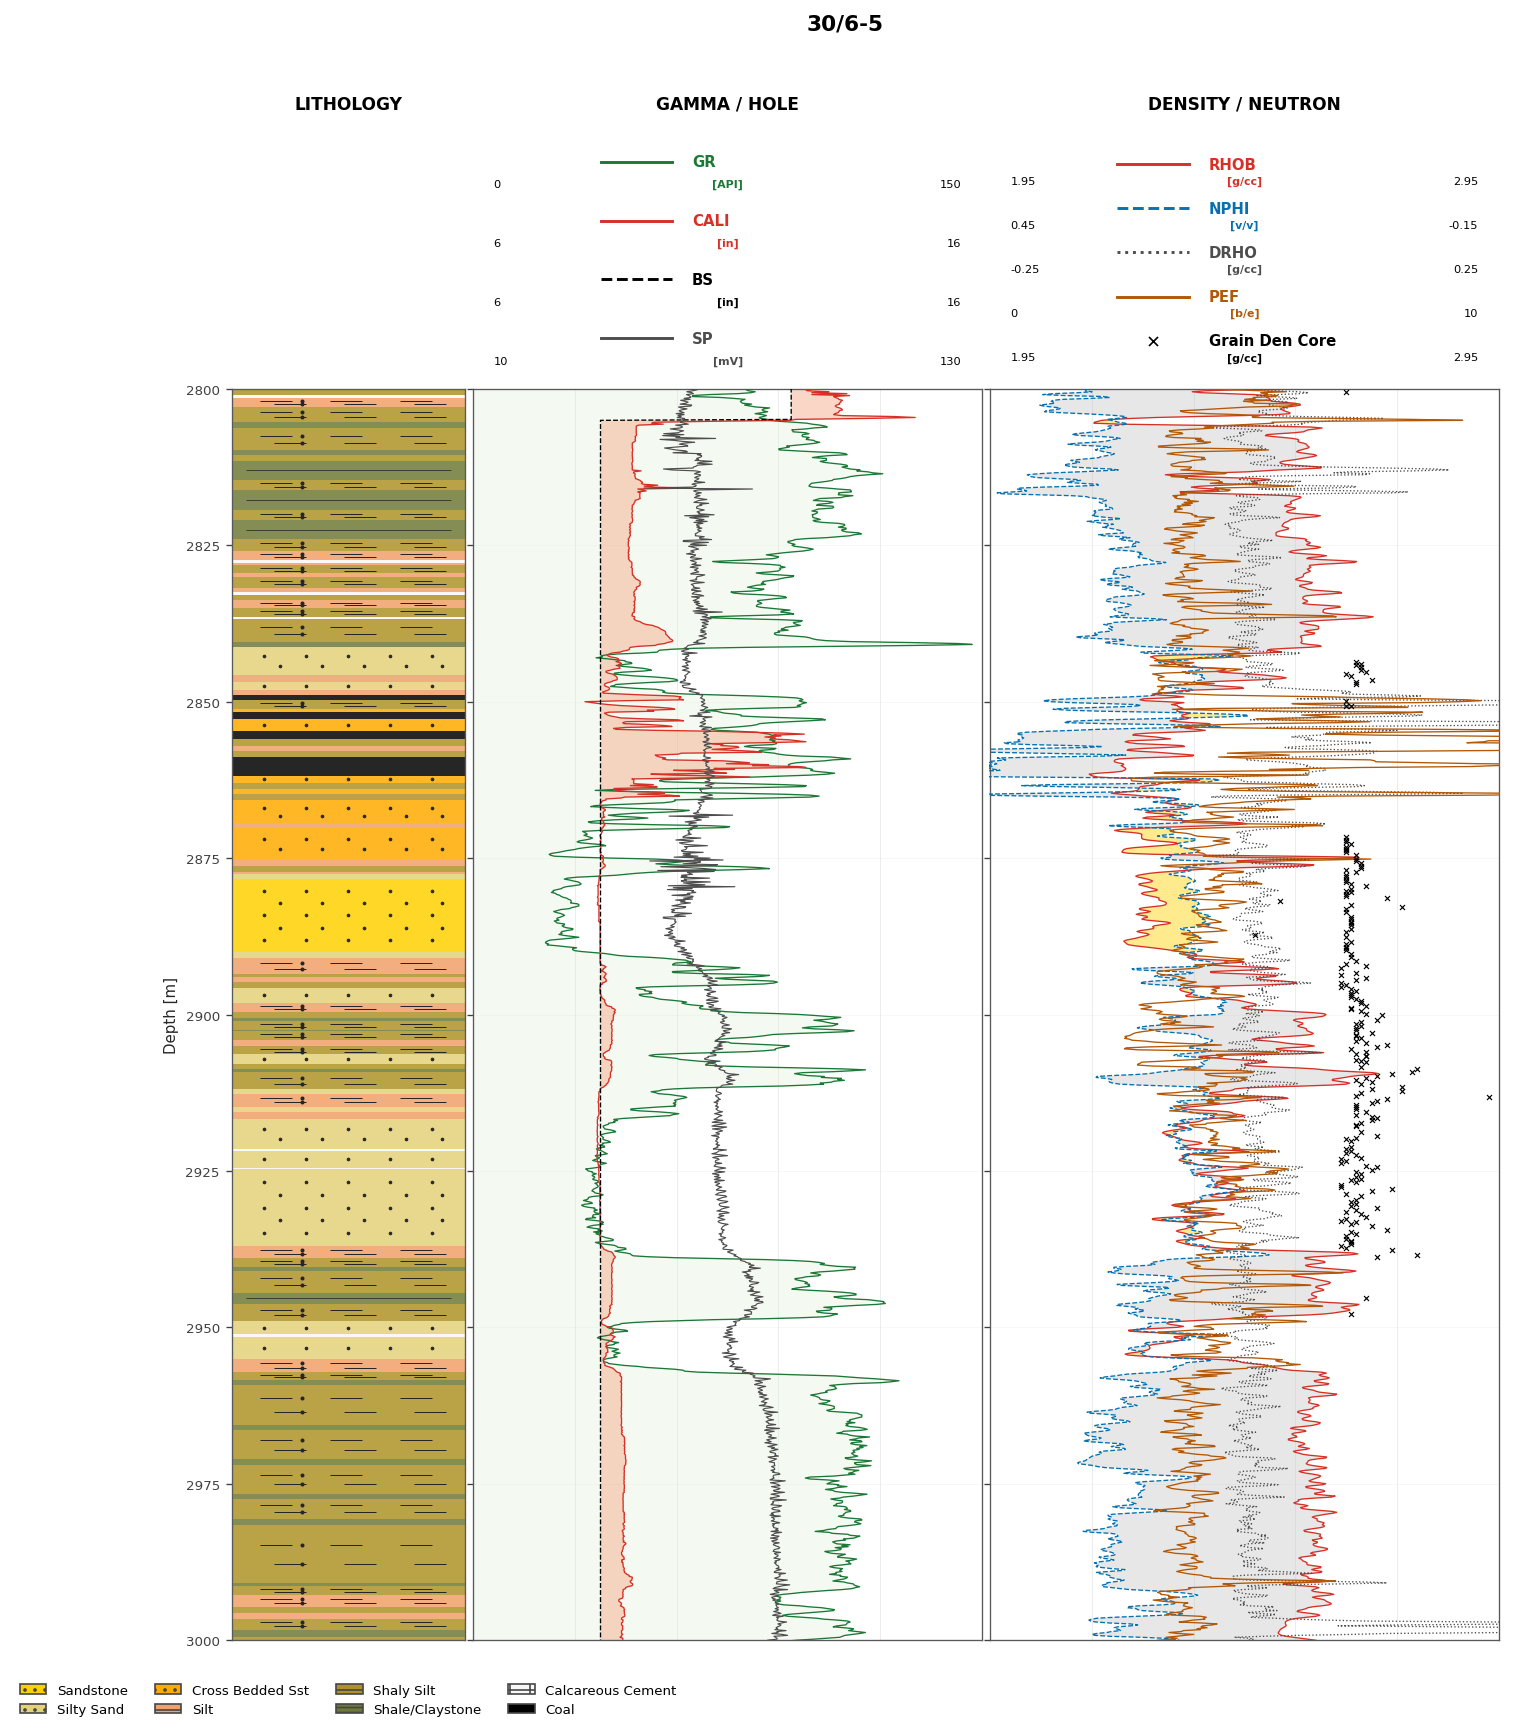

In [17]:
pp.plot(pp.read(pp.sample("30_6-5")), top=2800, bottom=3000,
        tracks=["LITHOLOGY", "GAMMA / HOLE", "DENSITY / NEUTRON"]).show()

The vendor codes resolve thin beds (silts inside the Brent Group sands, coal beds
in the Ness), while the interval file is a coarse column with one lithology per
formation-scale interval. The interval file takes precedence when both are
present; `lithology_source="vendor"` makes the interpretation use the codes
instead. Changing that one setting shows what the choice does to Brent Group
net pay.

In [18]:
vendor = pp.interpret(well, **SETTINGS, lithology_source="vendor")
pd.DataFrame({"interval file": result.summary(**BRENT)["net_thickness"],
              "vendor codes": vendor.summary(**BRENT)["net_thickness"]})

,interval file,vendor codes
depth_unit,m,m
net_rock,70.56,76.5
net_res,52.88,62.79
net_pay,22.4,26.21


With the vendor codes, Brent Group net reservoir grows from 52.9 to 62.8 m and
net pay from 22.4 to 26.2 m. The codes route each thin bed to its own matrix
and cutoff family, and the interpretation leaves out of net reservoir the
samples its lithology calls coal, which the coarse interval file cannot do. A
change of 4 m of pay from the lithology source alone is a reason to check the
source before quoting the number. The rest of the tour keeps the interval file.

---
## 5. Clay volume (VCL)

Clay volume drives every later step: it corrects porosity, feeds the shaly-sand
saturation models and is the first net-pay cutoff. The workflow computes three
estimates, from gamma ray (`VCL_GR`), spontaneous potential (`VCL_SP`) and
the neutron-density separation (`VCL_ND`), and keeps the **minimum** of the
gamma-ray and neutron-density estimates as `VCL`, on the reasoning that each
indicator can only overestimate clay. The step's decisions say which endpoints
it picked.

In [19]:
result.step("vclay").decisions

['GR_min = 21.6 (auto, P5 of GR)',
 'GR_max = 115.3 (auto, P95 of GR)',
 'Gamma-ray clay input: GR',
 'GR method: linear',
 'SP method: enabled',
 'N-D method: enabled',
 'SP_clean = 43.2 (auto, P5 of SP)',
 'SP_shale = 111.6 (auto, P95 of SP)',
 'Applied GR endpoints: 20 to 115.313 API',
 'GR baseline bound on automatic picks (clean at most 20 API, shale at least 100 API): the clean GR pick 21.6 API was lowered to 20',
 'Final VCL = min(GR, ND) at each depth, range: 0.000 - 1.000',
 'VCL_SP is reported but left out of the minimum: SP baselines picked over the whole log mostly measure SP baseline drift, so it only fills depths with no GR or N-D value. Set both sp_min and sp_max to include it; they apply to the whole log, so only for an SP without baseline drift',
 'N-D clean line (sandstone): RHOB 2.65 g/cm3 at NPHI -0.02 to RHOB 1.99 g/cm3 at NPHI 0.38',
 'N-D clay point: RHOB 2.164 g/cm3, NPHI 0.450, the median of 7829 good-hole shale-lithology samples at 955.679-3059.87 m',
 "VCL_ND

The GR endpoints are the 5th and 95th percentiles of the log, bounded to at
most 20 API (clean) and at least 100 API (shale): here 21.6 API, lowered to
20, and 115.3 API. `gr_min` and `gr_max` set them explicitly and are used as
given. The SP estimate joins the minimum only
when you set both SP baselines (`sp_min`, `sp_max`), because the SP baseline
drifts down most wells.

The `curves=` option of `pp.plot` draws chosen curves; here the three
estimates and the combined curve, in a track named after what it holds.

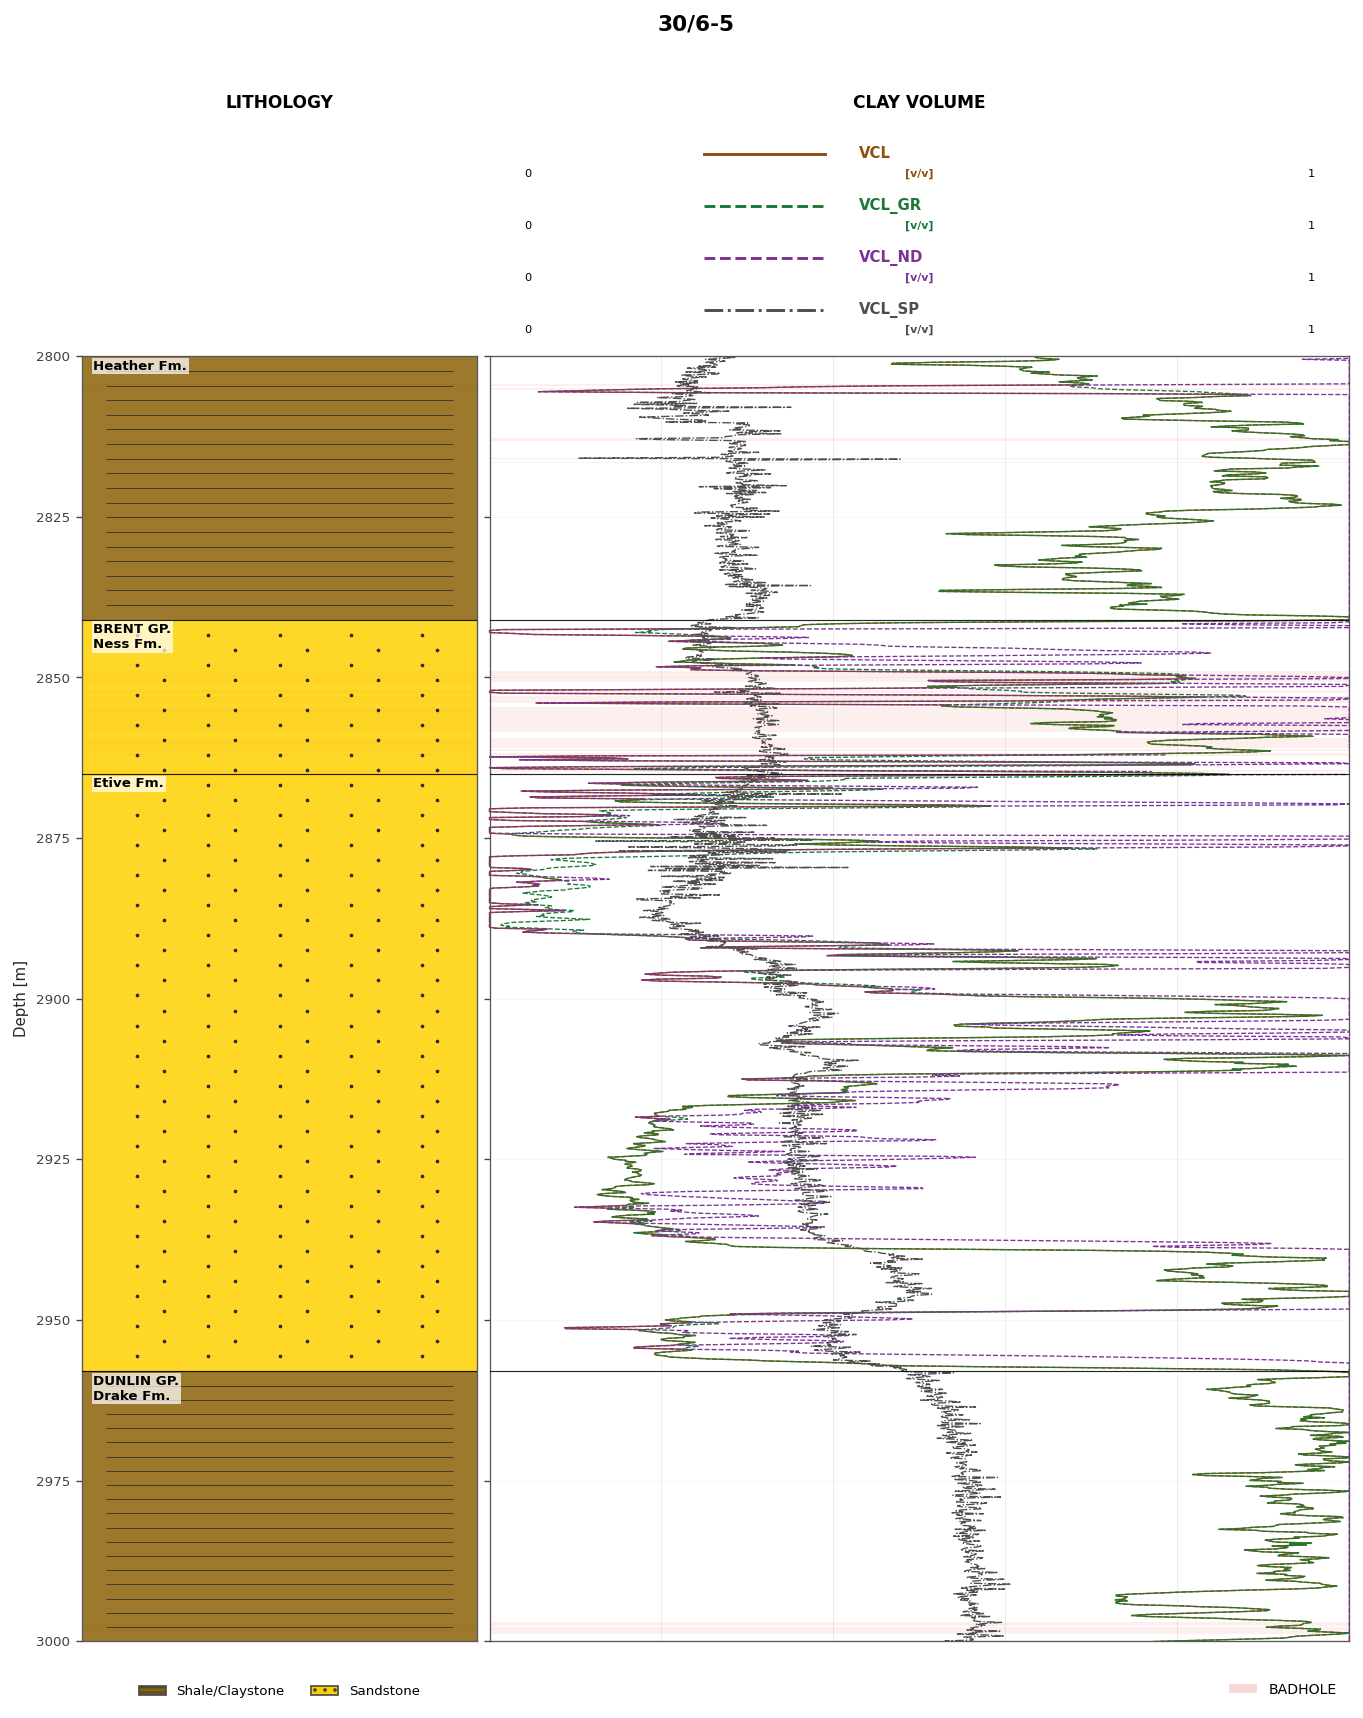

In [20]:
pp.plot(result, curves=["VCL_GR", "VCL_ND", "VCL_SP", "VCL"], top=2800, bottom=3000).show()

In the clean Etive sands all three estimates read low. In the shales above and
below, `VCL_GR` reads close to 1 and `VCL_ND` reaches 1 (it is held at 1 where
the samples plot at or beyond the clay point), so `VCL`, the lower of the
estimates, follows `VCL_GR`. `VCL_SP` reads between about 0.2 and
0.6 whether the rock is shale or sand: over this window the SP hardly separates
them, which is why it stays out of the minimum.

`gr_method` bends the linear gamma-ray index with the Larionov, Stieber or
Clavier transforms, which all give less clay. Each run below changes only that
setting; the table shows the Brent Group VCL statistics of each.

In [21]:
runs = {method: pp.interpret(well, **SETTINGS, gr_method=method)
        for method in ["linear", "larionov_older", "steiber", "clavier"]}
pd.concat({method: run.statistics(curves=["VCL"], **BRENT) for method, run in runs.items()})

,,unit,samples,mean,p10,median,p90
linear,VCL,v/v,768,0.382542,0.015305,0.263280,0.858434
larionov_older,VCL,v/v,768,0.295753,0.014400,0.177397,0.754785
steiber,VCL,v/v,768,0.249482,0.012751,0.136046,0.672482
clavier,VCL,v/v,768,0.281567,0.014009,0.165424,0.727700


The non-linear transforms lower the Brent Group median VCL from 0.26 (linear)
to 0.18 (Larionov, older rocks), 0.17 (Clavier) and 0.14 (Stieber). A clay
cutoff is therefore only meaningful together with the transform it was chosen
for. We keep the linear index, the default.

---
## 6. Porosity

The workflow computes density porosity `PHID`, sonic porosity `PHIS`, neutron
porosity `PHIN`, total porosity `PHIT` (an adaptive neutron-density
combination that falls back to density where the neutron is missing) and
effective porosity `PHIE = PHIT - VCL x phi_clay`. The matrix density is the
key assumption: `matrix_type="sandstone"` gives quartz, 2.65 g/cm3. 30/6-5
has measured core grain density, `GDEN`, so we can check it.

In [22]:
well.to_dataframe()["GDEN"].describe()

count    200.000000
mean       2.677850
std        0.053226
min        2.470000
25%        2.650000
50%        2.670000
75%        2.690000
max        3.060000
Name: GDEN, dtype: float64

The 200 plugs give a median grain density of 2.67 g/cm3 (mean 2.68), a little
above quartz. `rho_ma` sets the matrix density directly; one run with the core
value shows how much it matters.

In [23]:
grain = pp.interpret(well, **SETTINGS, rho_ma=2.67)
pd.concat({"quartz 2.65": result.statistics(curves=["PHIE"], **BRENT),
           "core grain density 2.67": grain.statistics(curves=["PHIE"], **BRENT)})

,,unit,samples,mean,p10,median,p90
quartz 2.65,PHIE,v/v,768,0.096004,0.0,0.099215,0.224216
core grain density 2.67,PHIE,v/v,768,0.099381,0.0,0.104688,0.230502


The heavier matrix raises the Brent Group median PHIE from 0.099 to 0.105 and
its 90th percentile from 0.224 to 0.231: a small shift, but one that carries
into every pore volume. Section 16 uses the plugs themselves to correct
density porosity.

The gamma-ray and porosity tracks of the interpretation plot show the curves against
the plugs.

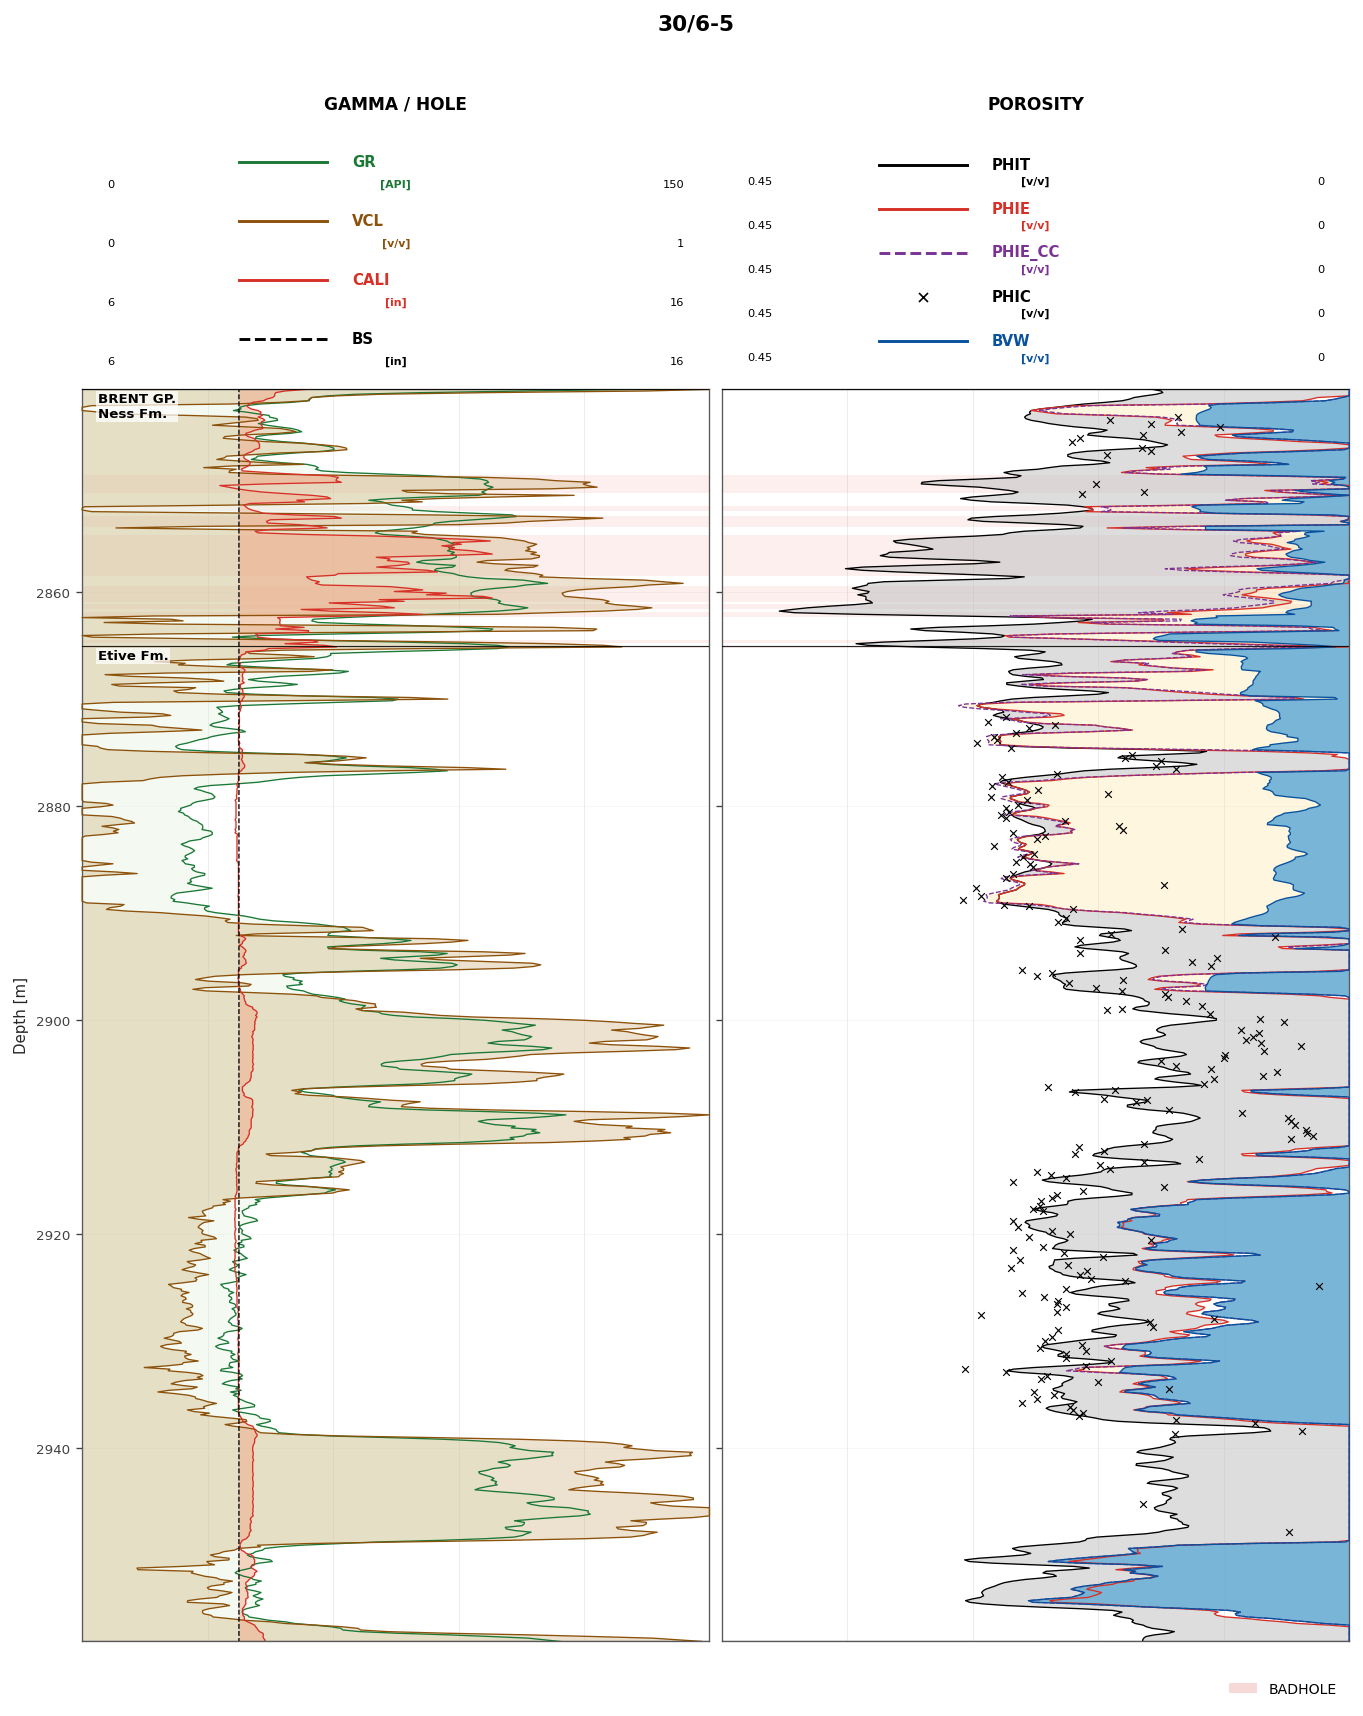

In [24]:
pp.plot(result, template="petrophysics", tracks=["GAMMA / HOLE", "POROSITY"], **BRENT).show()

The plugs (crosses) are helium porosity, a total porosity, so in shaly beds
expect them above `PHIE`; `PHIT` is the like-for-like curve there. The sonic
porosity `PHIS`, which the plot leaves out (`result.statistics(["PHID", "PHIS"])` compares
them), reads higher than the density porosity at nearly every Brent Group sample: the Wyllie equation has no compaction or shale correction, which is
why the workflow prefers density-based porosity. Section 16 quantifies the
log-core match.

---
## 7. Water saturation

Saturation needs the formation-water resistivity **at formation temperature**.
The workflow builds a temperature profile from the header BHT and a 68 degF
surface temperature, and moves our Rw (0.070 ohm.m at 230 degF) along it with
the Arps relation. The decisions of the two steps show the gradient and the Rw
correction; the last line is the saturation method used.

In [25]:
result.step("temperature").decisions + result.step("rw").decisions + [result.step("saturation").method]

['Temperature profile anchored to BHT metadata/input',
 'Gradient = 1.6354 F/100ft (29.81 C/km)',
 'Temp range: 77.5 - 258.8 F',
 'Rw corrected from 0.0700 ohm.m @ 230F along the temperature profile',
 'archie+simandoux']

The header BHT (126 degC, 258.8 degF at the 3556 m TD) gives a gradient of
1.64 degF/100 ft (29.8 degC/km), so formation temperature runs from 77.5 degF
near the surface to 258.8 degF at TD, and Rw is corrected along it. The
saturation step used Archie on clean samples and Simandoux on shaly ones
(`archie+simandoux`): with `sw_model="auto"` the salinity implied by the Rw
picks the shaly-sand equation.

`sw_model` chooses the equation. They differ in how they remove the
conductivity of clay: **Archie** has no clay term; **Simandoux** and
**Indonesia** (Poupon-Leveaux) add a clay conductance; the **North Sea** and
**Nigeria-Schlumberger** forms are variants with a shale exponent (`vsh_exp`,
`shale_exp`, 1.6 by default). `"auto"`, the default, uses Archie below the
clay cutoff and a shaly-sand equation above it. One run per model:

In [26]:
models = ["archie", "simandoux", "indonesia", "north_sea", "nigeria_schlumberger", "auto"]
runs = {model: pp.interpret(well, **SETTINGS, sw_model=model) for model in models}
pd.DataFrame({model: run.summary(**BRENT)["net_thickness"] for model, run in runs.items()}).T

,depth_unit,net_rock,net_res,net_pay
archie,m,70.56,52.88,22.4
simandoux,m,70.56,52.88,28.35
indonesia,m,70.56,52.88,28.19
north_sea,m,70.56,52.88,24.08
nigeria_schlumberger,m,70.56,52.88,24.54
auto,m,70.56,52.88,22.4


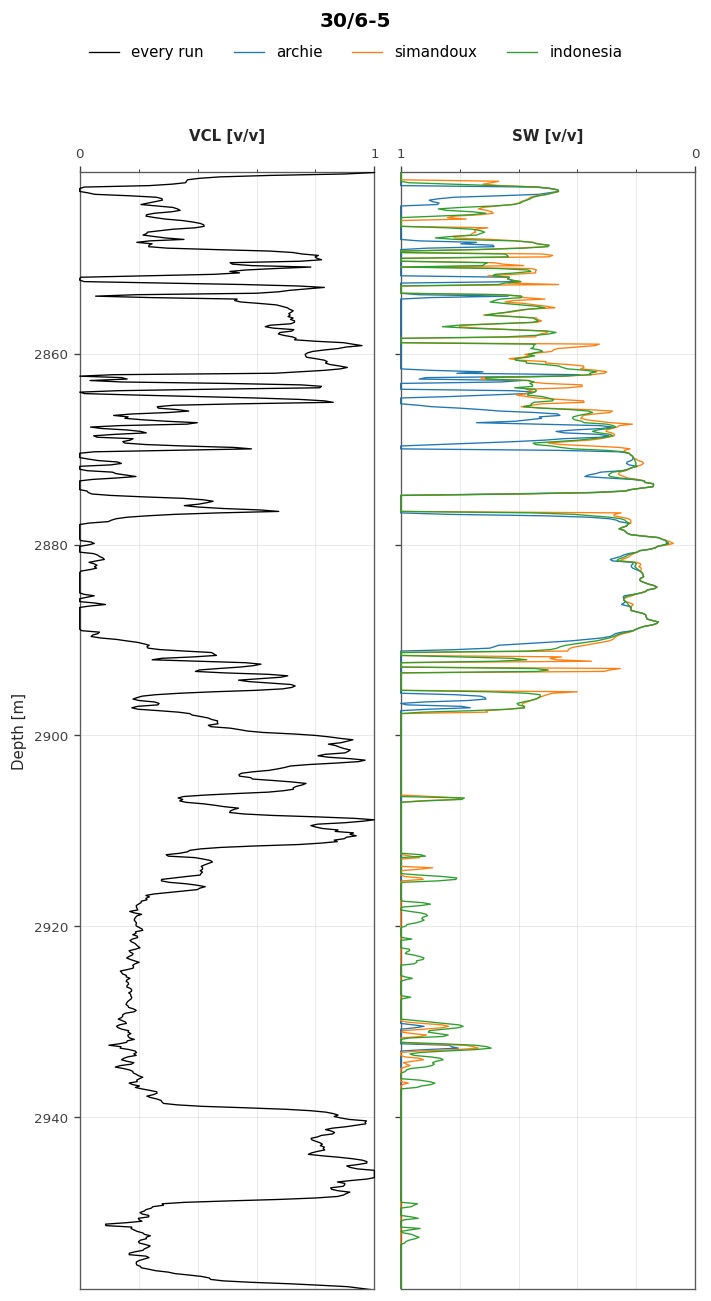

In [27]:
pp.plot({model: runs[model] for model in ["archie", "simandoux", "indonesia"]}, curves=["VCL", "SW"], **BRENT)

Net rock and net reservoir do not depend on the saturation model; net pay
does, from 22.4 m (Archie) to 28.4 m (Simandoux). `"auto"` gives the same pay
as Archie: it switches to a shaly-sand equation only above the clay cutoff,
where no sample can be pay anyway. The shaly-sand models add pay in the
moderately shaly beds, where they remove part of the conductivity as clay. The
spread, 6 m, measures how much the answer depends on the clay term; lesson 07
compares the models in depth.

A mapping of runs to `pp.plot` labels each run's curve. VCL is the same in
every run; Sw agrees in the clean upper Etive and parts in the shaly Ness beds
(about 2846-2870 m), where Archie reads close to 1 (median 0.89), Simandoux about
0.6 and Indonesia about 0.5. In the shales of the lower Etive (2898-2912 m and
2940-2950 m) there is no effective porosity, and every model reads 1. A low Sw in
beds that are mostly clay is the clay term over-correcting, not hydrocarbon; the clay cutoff keeps those beds
out of net pay.

Dual Water and Waxman-Smits need a measured bound-water resistivity (`rwb`)
and cation exchange capacity (`cec`, `b_coeff`); the library does not guess
them, so they are left out here.

---
## 8. Permeability

Log permeability is always a correlation. `perm_method` chooses it: the
Timur, Coates-Denoo and Wyllie-Rose equations use porosity and irreducible
water saturation, `lith_vcl` a lithology and clay correlation, and `"auto"`
(the default) also fits a transform to the core where the well has plugs,
written as `PERM_CC`. `calibrate_permeability` compares a log curve with the
plugs; `core_data` collects the plugs stored as curves.

In [28]:
from petrophys.interpretation.core_analysis import core_data, calibrate_permeability

core = core_data(result)
runs = {method: pp.interpret(well, **SETTINGS, perm_method=method) for method in ["timur", "coates", "wyllie_rose", "lith_vcl"]}
pd.Series({**{method: calibrate_permeability(run, core) for method, run in runs.items()},
           "core-calibrated PERM_CC": calibrate_permeability(result, core, log_curve="PERM_CC")})

timur                       CalibrationResult(Permeability (PERM, log10): n=144, R^2=0.510, bias=-1.3637, RMSE=1.8788, log = 1.067*core + -1.4915)
coates                      CalibrationResult(Permeability (PERM, log10): n=122, R^2=0.407, bias=-1.0809, RMSE=1.4073, log = 0.688*core + -0.3933)
wyllie_rose                 CalibrationResult(Permeability (PERM, log10): n=144, R^2=0.501, bias=-2.0052, RMSE=2.6507, log = 1.363*core + -2.6927)
lith_vcl                      CalibrationResult(Permeability (PERM, log10): n=198, R^2=0.706, bias=0.1876, RMSE=1.0952, log = 1.059*core + 0.1144)
core-calibrated PERM_CC    CalibrationResult(Permeability (PERM_CC, log10): n=135, R^2=0.419, bias=0.0082, RMSE=0.9789, log = 0.528*core + 0.9319)
dtype: object

Read the bias as log10(log) - log10(core): -1 means the log reads ten times
too low on average. The Swirr-based equations (Timur, Coates-Denoo,
Wyllie-Rose) all read low, by a factor of 10 to 100: at the many plugs where
the workflow's PHIE is zero (shaly beds it treats as shale, section 16) their
permeabilities collapse towards zero while the plugs measure tenths to a few
mD. The core-calibrated `PERM_CC` is computed from core-corrected porosity on
the core-porosity scale. It is written only where the clay volume is below the
net-rock cutoff and the porosity lies within the plugs' range, so it is compared at 135 plugs;
there it matches best on average (bias +0.01, RMSE 0.98). `lith_vcl`
correlates best (R² 0.71, bias +0.19, over all 198 plugs). Each
comparison uses only the plugs where its curve is defined, so `n` differs.
Section 16 fits a transform to the plugs themselves.

---
## 9. Net pay

Net-pay flags decide which depths count. The workflow writes three nested
flag curves:

- `NET_ROCK`: VCL below the clay cutoff;
- `NET_RES`: net rock with PHIE above the porosity cutoff (and not bad hole);
- `NET_PAY`: net reservoir with Sw below the saturation cutoff.

`result.summary()` adds them up over the whole well, and over a window with
`top` and `bottom`.

In [29]:
pd.DataFrame({"whole well": result.summary()["net_thickness"],
              "Brent Group": result.summary(**BRENT)["net_thickness"]})

,whole well,Brent Group
depth_unit,m,m
net_rock,1978.92,70.56
net_res,752.85,52.88
net_pay,33.07,22.4


The whole well has 33.1 m of net pay against 22.4 m in the Brent Group, and
almost 2000 m of net rock. Most of the difference is **not** reservoir:
shallow, poorly compacted sediments read very high porosity and little clay,
and with that much porosity even modest resistivity gives a low Sw, so they
pass all three cutoffs. Cutoffs flag log values; they do not know where the
reservoir is. That is why every reservoir number in this tour is taken over
the Brent Group window or per formation.

---
## 10. Formation and zone summaries

`result.formation_summary()` rolls the curves up by formation: gross, net
rock, net reservoir and net pay thickness, net-to-gross, and PHIE, Sw, VCL and
permeability averaged over the **net-pay samples** of each formation. The tops
mix levels, so it summarizes the formation rank by default, and no interval is
counted twice.

In [30]:
result.formation_summary()

,Formation,Top,Bottom,Gross (m),Net Rock (m),Net Reservoir (m),Net Pay (m),N/G (reservoir),Pay/Gross,Avg PHIE,...,Avg GR,Avg RHOB,Avg NPHI,Avg RDEP,Avg PHIT,HCPV,BVW,Samples,Pay Samples,Data Coverage %
0,Utsira Fm.,726.0,879.0,153.009585,153.009585,0.000000,0.000000,0.000000,0.000000,NaN,...,23.585961,1.890262,NaN,1.078117,0.460447,NaN,NaN,1004,0,100.000000
1,Balder Fm.,1908.0,2023.0,115.062070,81.534060,53.797370,1.523980,0.467551,0.013245,0.357081,...,49.051953,2.196579,0.422368,1.087175,0.341828,0.232686,0.204398,755,10,100.000000
2,Sele Fm.,2023.0,2123.0,99.974425,87.020810,11.582345,0.000000,0.115853,0.000000,NaN,...,50.666692,2.196131,0.433307,0.842791,0.346366,NaN,NaN,656,0,100.000000
3,Lista Fm.,2123.0,2203.0,80.010010,79.095580,44.348025,0.304805,0.554281,0.003810,0.349146,...,45.935849,2.264676,0.393734,1.127755,0.305611,0.043932,0.205014,525,2,100.000000
4,Draupne Fm.,2452.0,2593.0,140.970215,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,...,132.165687,2.346621,0.414795,2.253133,0.284338,NaN,NaN,925,0,100.000000
5,Heather Fm.,2593.0,2841.0,247.954590,14.325800,0.762205,0.304810,0.003074,0.001229,0.280060,...,78.887398,2.513832,0.347220,5.053931,0.196535,0.040024,0.148751,1627,2,100.000000
6,Ness Fm.,2841.0,2865.0,24.079345,9.905895,5.333865,1.524050,0.221512,0.063293,0.212012,...,75.011563,2.316351,0.310226,4.190753,0.253417,0.156445,0.109361,158,10,100.000000
7,Etive Fm.,2865.0,2958.0,92.963870,60.655520,47.548695,20.878775,0.511475,0.224590,0.218886,...,56.143401,2.406742,0.224805,9.416561,0.186621,3.492424,0.051614,610,137,100.000000
8,Drake Fm.,2958.0,3071.0,113.081050,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,...,102.970216,2.573988,0.297030,4.925372,0.154480,NaN,NaN,742,0,100.000000
9,Cook Fm.,3071.0,3123.0,51.968265,10.515870,0.000000,0.000000,0.000000,0.000000,NaN,...,68.140303,2.509150,0.229025,5.483931,0.151208,NaN,NaN,341,0,100.000000


The Etive Fm. carries 20.9 m of the pay (pay/gross 0.22, pay-averaged PHIE
0.22 and Sw 0.24) and the Ness Fm. 1.5 m. The flags in the shallow Balder and
Lista formations and in the Heather Fm. mudstone (1.5, 0.3 and 0.3 m) and the
0.6 m in the Statfjord Group are a question for geological review, not pay:
one Rw serves the whole well although shallow formation water is usually
fresher. The `Avg Perm` column averages the core-calibrated `PERM_CC` where it
is written (clay volume below the cutoff, porosity within the plugs' range) and
the empirical `PERM` at the other pay samples.

`rank="group"` summarizes the groups instead. Groups without formation picks
appear only here: the Hordaland Group carries 7.8 m of flagged "pay" in soft
Tertiary mudstone, the main reason the whole-well total exceeds the
formation rows.

In [31]:
result.formation_summary(rank="group")

,Formation,Top,Bottom,Gross (m),Net Rock (m),Net Reservoir (m),Net Pay (m),N/G (reservoir),Pay/Gross,Avg PHIE,...,Avg GR,Avg RHOB,Avg NPHI,Avg RDEP,Avg PHIT,HCPV,BVW,Samples,Pay Samples,Data Coverage %
0,NORDLAND GP.,181.0,726.0,544.982485,160.324825,0.000000,0.000000,0.000000,0.000000,NaN,...,58.416758,1.901390,NaN,5.409345,0.451979,NaN,NaN,3576,0,100.0
1,HORDALAND GP.,879.0,1908.0,1029.004855,1017.574780,536.447785,7.772365,0.521327,0.007553,0.451708,...,39.165429,1.958369,0.521568,0.968778,0.463116,1.474158,0.262042,6752,51,100.0
2,ROGALAND GP.,1908.0,2203.0,295.046505,247.650450,109.727740,1.828785,0.371900,0.006198,0.355759,...,48.754078,2.214894,0.418310,1.015372,0.333544,0.276618,0.204501,1936,12,100.0
3,SHETLAND GP.,2203.0,2408.0,204.978030,106.680265,21.944450,0.152465,0.107058,0.000744,0.352727,...,57.746287,2.390926,0.367970,1.411724,0.259144,0.023155,0.200858,1345,1,100.0
4,CROMER KNOLL GP.,2408.0,2452.0,44.043455,36.423585,2.743290,0.000000,0.062286,0.000000,NaN,...,49.308739,2.488522,0.292714,1.612687,0.194797,NaN,NaN,289,0,100.0
5,VIKING GP.,2452.0,2841.0,388.924805,14.325800,0.762205,0.304810,0.001960,0.000784,0.280060,...,98.198690,2.453225,0.371713,4.038752,0.228360,0.040024,0.148751,2552,2,100.0
6,BRENT GP.,2841.0,2958.0,117.043215,70.561415,52.882560,22.402825,0.451821,0.191406,0.218418,...,60.025133,2.388146,0.242378,8.341460,0.200363,3.648869,0.055543,768,147,100.0
7,DUNLIN GP.,2958.0,3223.0,265.023925,10.515870,0.000000,0.000000,0.000000,0.000000,NaN,...,92.734237,2.573257,0.271202,5.356347,0.144761,NaN,NaN,1739,0,100.0


Any other set of intervals goes through `result.zone_summary(zones)`, with a
name, top and bottom per zone. Here the Ness and the Etive split at its
mid-depth (an **illustrative** halving, not a geological pick).

In [32]:
result.zone_summary([{"zone": "Ness Fm.", "top": 2841, "bottom": 2865},
                     {"zone": "Etive upper half", "top": 2865, "bottom": 2911.5},
                     {"zone": "Etive lower half", "top": 2911.5, "bottom": 2958}])

,Zone,Top,Bottom,Gross (m),Net Rock (m),Net Reservoir (m),Net Pay (m),N/G (reservoir),Pay/Gross,Avg PHIE,...,Avg GR,Avg RHOB,Avg NPHI,Avg RDEP,Avg PHIT,HCPV,BVW,Samples,Pay Samples,Data Coverage %
0,Ness Fm.,2841.0,2865.0,24.079345,9.905895,5.333865,1.524050,0.221512,0.063293,0.212012,...,75.011563,2.316351,0.310226,4.190753,0.253417,0.156445,0.109361,158,10,100.0
1,Etive upper half,2865.0,2911.5,46.482055,28.194090,24.688965,20.878775,0.531150,0.449179,0.218886,...,56.378568,2.388885,0.222262,16.068465,0.192175,3.492424,0.051614,305,137,100.0
2,Etive lower half,2911.5,2958.0,46.481815,32.461430,22.859730,0.000000,0.491799,0.000000,NaN,...,55.908235,2.424599,0.227347,2.764657,0.181067,NaN,NaN,305,0,100.0


All of the Etive pay is in its upper half, and the lower half is wet,
consistent with the high resistivity over low resistivity seen in section 1.

For the distribution of each property in a window, `result.statistics(top=,
bottom=)` reports statistics of the main curves over every sample.

In [33]:
result.statistics(**BRENT)

,unit,samples,mean,p10,median,p90
VCL,v/v,768,0.382542,0.015305,0.263280,0.858434
PHIT,v/v,768,0.200363,0.129854,0.203476,0.263334
PHIE,v/v,768,0.096004,0.000000,0.099215,0.224216
SW,v/v,768,0.793919,0.231499,1.000000,1.000000
PERM,mD,554,72.363724,0.000000,6.338853,298.464270


---
## 11. Reading the trace

`result.print_trace()` prints every step with its method, inputs, outputs,
parameters and decisions: the full record of what the interpretation did and
why. It is long, so scroll through it; the first lines give the overall
status, the lithology domain and the Rw, Rmf and clay resistivity used.

In [34]:
result.print_trace()


WORKFLOW TRACE: 30/6-5
Overall: SUCCESS | Executed: 18 | Skipped: 4
Lithology domain: clastic
Rw = 0.0624-0.1967 ohm.m | Rmf = 0.0246-0.0776 | Rcl = 1.3250

[OK  ] normalization
       Method: curve_alias_and_unit_standardization
       Inputs: BS, CALI, DRHO, DTC, DTE, GDEN, GR, KH_CORE, KV_CORE, LITHOLOGY_GEOLINK, NPHI, PEF, PHIC, RDEP, RHOB, RMED, RSHA, SOC, SP, SWC
       Outputs: DRHO, PEF, GR, DTC, SWC, SOC
       rename_curves: False
       convert_units: True
       rename_map: {}
       working_aliases: {}
       unit_changes: {'NPHI': {'from': 'm3/m3', 'to': 'v/v'}, 'GR': {'from': 'gAPI', 'to': 'API'}, 'SWC': {'from': 'frac', 'to': 'v/v'}, 'SOC': {'from': 'frac', 'to': 'v/v'}}
       core_saturation_normalization: {'SWC': {'original_unit': 'frac', 'source_unit': None, 'target_unit': 'v/v', 'factor': 0.01, 'reason': 'inferred_percent', 'masked_count': 0, 'warnings': ["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]}, 'S

Settings are validated when they are given: a misspelt name or an invalid
value raises an error with a suggestion instead of being silently ignored.

In [35]:
try:
    pp.interpret(well, sw_modle="archie")
except TypeError as error:
    print(error)

Unknown interpretation setting(s): 'sw_modle' (did you mean 'sw_model'?). See petrophys.DynamicWorkflowConfig for the available settings.


In [36]:
try:
    pp.interpret(well, sw_model="simandoox")
except ValueError as error:
    print(error)

Invalid DynamicWorkflowConfig:
  - sw_model='simandoox' is not valid; use one of: auto, archie, north_sea, nigeria_schlumberger, simandoux, modified_simandoux, indonesia, dual_water, waxman_smits (did you mean 'simandoux'?)


`pp.interpret` leaves the well you pass unchanged. `inplace=True` adds the
calculated curves to it instead, for when you deliberately want to fill an
existing `Well`.

In [37]:
in_place = pp.read(pp.sample("30_6-5"))
pp.interpret(in_place, **SETTINGS, inplace=True)
in_place

Well(30/6-5, curves=62, samples=22176)

---
## 12. Multi-well comparison

`pp.read` of a list (or a folder) reads several wells, and `pp.interpret`
interprets each with the same settings; LAS header values fill each well's
unset settings from its own header. We pass the cutoffs and the clastic
domain and leave Rw to each well. `results.summary()` gives one row per well.

In [38]:
wells = pp.read([pp.sample(name) for name in ["30_6-5", "25_5-1", "16_7-1", "15_9-14"]])
results = pp.interpret(wells, lithology="clastic", vcl_cutoff=0.40, phie_cutoff=0.10, sw_cutoff=0.60)
results.summary()

,Well,Status,Depth unit,Net rock,Net reservoir,Net pay,Median VCL,Median PHIE,Median SW,Median PERM,Warnings
0,30/6-5,interpreted,m,2013.66,788.21,48.92,0.321619,0.318370,0.863708,15.332005,4
1,25/5-1 Froey,interpreted,m,2309.47,1522.78,236.68,0.261913,0.256878,0.903417,2874.812420,5
2,16/7-1,interpreted,m,365.76,158.19,1.07,0.508790,0.149206,1.000000,83.607593,6
3,15/9-14,interpreted,m,1358.03,813.82,26.21,0.459303,0.228902,0.750849,112.545293,9


The read prints `DataQualityWarning`s from the input screening (section 3);
each names its curve and how many samples it removed. One is **15/9-14's `DTE`
curve** (a second compressional sonic): every sample lies outside the plausible
range although it is labelled us/ft, so the whole curve is removed. Nothing
else in that well depends on `DTE`. 16/7-1 loses its whole sonic the same way: half
its `DTC` samples are implausible, so the rest is left out too. `results["15/9-14"].warnings` lists the
well's notes, including that it has no BHT, so its temperatures follow an
assumed 30 degC/km gradient.

The net-pay column is a whole-well total, with the shallow-section flags of
section 9; it ranks nothing until each well has a reservoir window. The rw step
of each trace says where its Rw came from:

In [39]:
results["15/9-14"].warnings

['Held readings, one value repeated exactly over ten samples or more: RXO 3.135 over 3555.8-3573.18 m (116 samples), GR 94.188 over 3564.79-3573.18 m (57 samples), NPHI 0.23975 over 3573.18-3575.31 m (16 samples), NPHI 0.23926 over 3568.3-3570.13 m (14 samples), RDEP 2.041 over 3568.15-3569.67 m (12 samples) and 3 more. A tool that stopped reading, or a log padded to a depth, holds its last value while the other logs change; check these against the other logs before using them.',
 'DTE: 20181 of 20181 samples are outside the plausible DTE range 20 to 600 us/ft and were removed.',
 "RSHA: 13 of 20295 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.",
 "RXO: 6 of 4059 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.",
 "RMED: 13 of 20295 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed

In [40]:
pd.Series({run.well.name: run.step("rw").decisions for run in results})

30/6-5                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           [Rw corrected from LAS metadata: 0.0700 ohm.m @ 230F along the temperature profile]
25/5-1 Froey                                                                                                                                                                                                                                                                                                                                                       

30/6-5 and 25/5-1 take Rw from their LAS headers (0.070 ohm.m at 230 degF and
0.047 ohm.m at 200 degF). 16/7-1 and 15/9-14 have none, so the workflow
estimates Rw from the SP; with a static SP of only about -10 mV that estimate
is weak, and their saturations are screening numbers only. For 16/7-1 the rw
step says so itself: in its clean, porous rock the apparent water resistivity is
only 0.14 of the SP-derived Rw, so Archie puts Sw above 1 and the workflow
holds it at 1 (the median Sw of 1.0 in the table). That Rw needs a water
sample; case study CS4 works through this well. 16/7-1 also has no
neutron log, so its mineral solve is skipped, and neither of these two wells
has core.

With `curves=`, `pp.plot` of several wells draws one figure, a track per
curve and every well in each track.

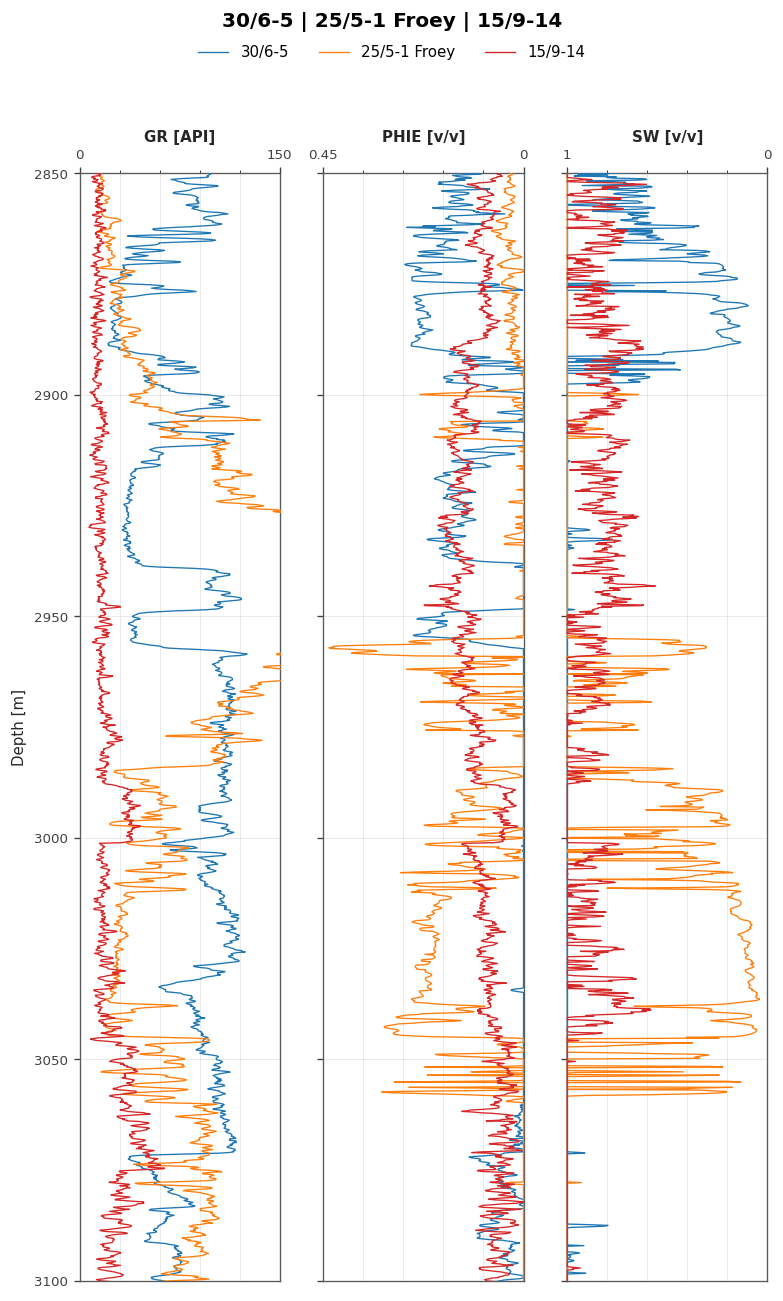

In [41]:
pp.plot(results, curves=["GR", "PHIE", "SW"], top=2850, bottom=3100).show()

At the same depth the wells are in different rocks: 30/6-5 in the Brent Group
and Dunlin shale; 25/5-1 in a hot shale (GR reaching about 300 API, off the 0-150 API scale) over a clean, low-Sw
sand near 3010-3040 m; 15/9-14 in a low-GR section of its own; and 16/7-1 is
not logged this deep. Comparing wells by depth
shows their logs side by side; comparing their reservoirs needs a tops table
for each well (`formations=` with a `well` column), and then
`results.formation_summary()` gives one table across the wells.

---
## 13. Rock quality and flow units

The workflow also writes the standard reservoir-quality curves:

- **Bulk volume water** `BVW = PHIE x Sw`. At irreducible saturation BVW is
  roughly constant within a comparable rock type. A hyperbola in a PHIE-Sw
  crossplot (a Buckles plot) identifies constant BVW; independent evidence is
  needed to establish irreducible saturation or predict water production.
- **Rock quality index** `RQI = 0.0314 sqrt(k / PHIE)` (micrometres), the
  **normalized porosity** `PHI_Z = PHIE / (1 - PHIE)`, and the **flow zone
  indicator** `FZI = RQI / PHI_Z`. Rock with similar FZI flows alike (a
  hydraulic flow unit).

In [42]:
result.statistics(curves=["BVW", "RQI", "PHI_Z", "FZI"], **BRENT)

,unit,samples,mean,p10,median,p90
BVW,v/v,768,0.057855,0.000000,0.045453,0.143751
RQI,microns,486,1.167909,0.188769,0.913654,2.462663
PHI_Z,v/v,545,0.161676,0.035435,0.151812,0.309965
FZI,microns,484,6.923907,2.027552,5.787687,11.936636


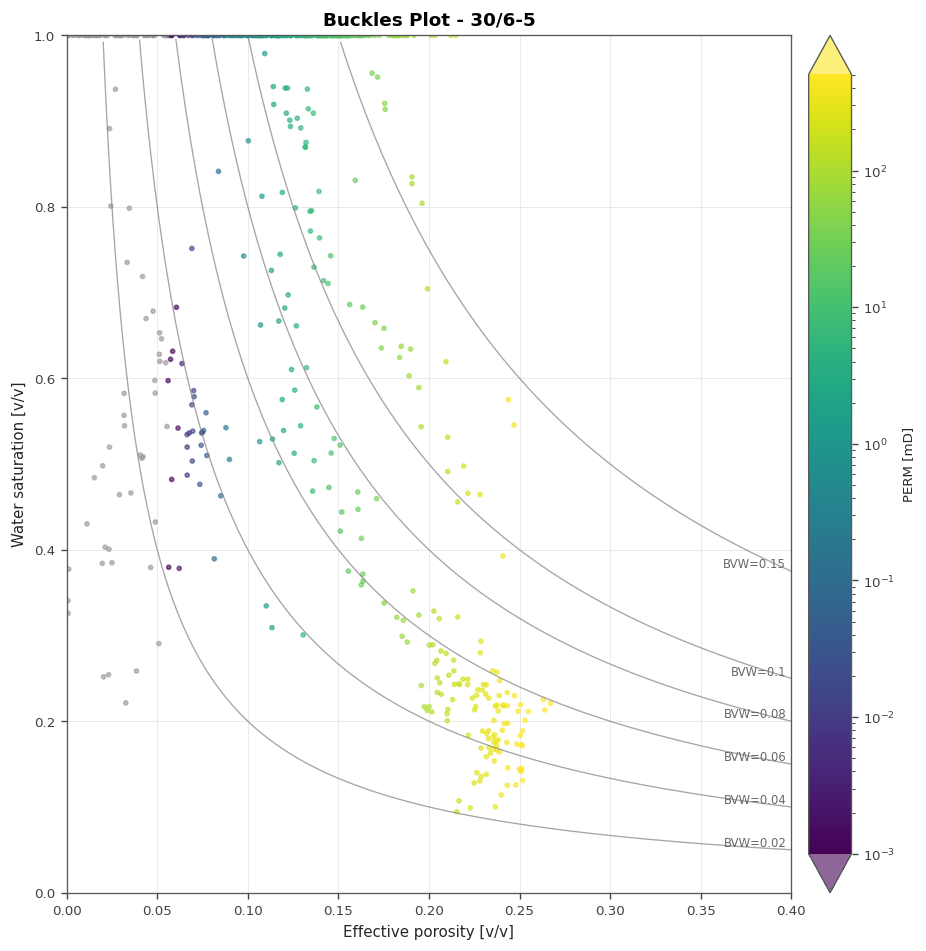

In [43]:
pp.crossplot(result, "PHIE", "SW", top=2841, bottom=2958)

In the Brent Group, half the samples have BVW below 0.045 and the median FZI
is 5.8 um. The Buckles plot shows the pay samples (Sw 0.1-0.3, PHIE above
0.2) clustered between the BVW 0.04 and 0.06 hyperbolas. This describes their
bulk-volume water; it does not alone establish irreducible saturation. Grey points have no log permeability to colour them
(PERM zero or missing): the tight, shaly samples. Samples without effective porosity
have Sw = 1 and sit in the corner at PHIE = 0, Sw = 1.

Flow units are best defined on core, where porosity and permeability are both
measured. `calculate_flow_units(core)` groups the plugs by FZI, and
`pp.crossplot(core, "PHI_Z", "RQI")` draws each unit as a line of constant FZI in
RQI-phi_z space; `.summary()` counts the plugs and gives the mean FZI per unit.

,Samples,Mean FZI
HFU,,
1,44,0.333813
2,30,0.640174
3,23,1.402861
4,28,2.885503
5,40,4.783247
6,33,8.950909


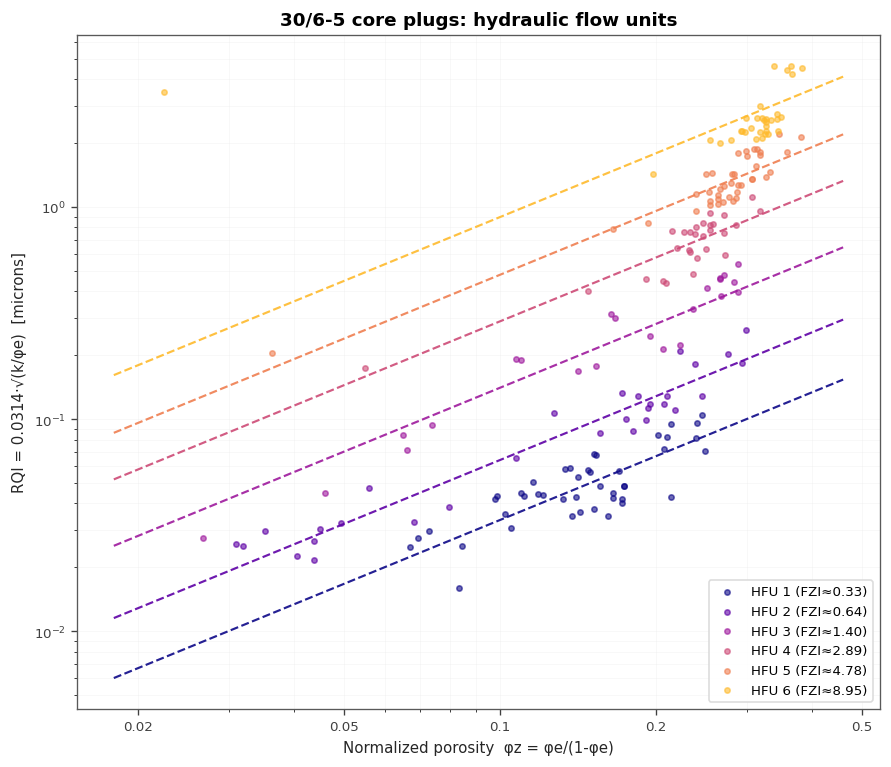

In [44]:
from petrophys.evaluation import calculate_flow_units
pp.crossplot(core, "PHI_Z", "RQI", title="30/6-5 core plugs: hydraulic flow units")
calculate_flow_units(core).summary()

The plugs fall into six flow units with mean FZI from 0.33 to 8.95 um. Points
along one line flow alike whatever their porosity; at a porosity of 0.2 the
units differ in permeability by more than two orders of magnitude, so one
poro-perm transform (section 16) averages over several rock types. One plug stands apart: at
2924.84 m it measures 273 mD at 2 % porosity, an FZI of about 155 um against 13 for the next
highest, far above every line. A cracked or broken plug reads that way; check it before it
weighs on a unit.

---
## 14. In-place volumes

The `HCPV` column of the formation summary is a thickness: the sum of
PHIE x (1 - Sw) x step over the pay samples. Turning it into a volume needs an
area and fluid properties, which no log provides. `ooip` takes the
net pay (in feet), the pay-averaged porosity and saturation, an area and a
formation volume factor. The cell uses **illustrative assumptions** (a 640-acre
drainage area, Bo = 1.2 rb/stb and the library's default recovery factor) with
the Brent Group row of the group summary. The result shows the arithmetic; it
is not a resource estimate.

In [45]:
from petrophys.evaluation.summaries import ooip

brent = result.formation_summary(rank="group").set_index("Formation").loc["BRENT GP."]
ooip(area_acres=640, net_pay_ft=brent["Net Pay (m)"] * 3.28084,
     porosity=brent["Avg PHIE"], sw=brent["Avg Sw"], bo=1.2)

{'ooip_stb': np.float64(49535229.483720265),
 'ooip_mbbl': np.float64(49535.229483720264),
 'ooip_mmbbl': np.float64(49.535229483720265),
 'ooip_m3': np.float64(7875472.390497079),
 'recoverable_stb': np.float64(14860568.845116079),
 'recoverable_mbbl': np.float64(14860.568845116079),
 'recovery_factor': 0.3}

The Brent Group row gives 22.4 m (73.5 ft) of pay with PHIE 0.218 and Sw 0.254.
Over the assumed 640 acres that is 49.5 million stock-tank barrels in place and
14.9 million recoverable at the default 30 % recovery factor. Every input but
the three log numbers is an assumption.

---
## 15. Exporting results

`result.to_las` writes every curve with the settings used in the header, and
`result.to_json` the complete trace. A summary table is a pandas DataFrame,
so `to_csv` or `to_excel` writes it. `pp.export_context` writes a bounded JSON
summary of the interpreted well for an LLM (lesson 19). We write into a
temporary folder and read the LAS file back.

In [46]:
import tempfile
from pathlib import Path

folder = Path(tempfile.mkdtemp())
pp.read(result.to_las(folder / "30_6-5_interpreted.las"))

Well(30/6-5, curves=59, samples=22176)

In [47]:
result.to_json(folder / "30_6-5_trace.json")
result.formation_summary().to_csv(folder / "30_6-5_formations.csv", index=False)
pp.export_context(result, folder / "30_6-5_context.json")
sorted(path.name for path in folder.iterdir())

['30_6-5_context.json',
 '30_6-5_formations.csv',
 '30_6-5_interpreted.las',
 '30_6-5_trace.json']

---
## 16. Core data and log-core calibration

30/6-5 stores its laboratory measurements as LAS curves: `PHIC` (helium
porosity), `KH_CORE` and `KV_CORE` (Klinkenberg permeability), `GDEN` (grain
density), and `SWC`/`SOC` (Dean-Stark saturations). Only the plug depths hold
values. `core_data` (section 8) collected them into the `CoreData`
object `core`.

In [48]:
core.to_dataframe().describe()

,DEPTH,CPOR,CPERM,CGD,CSW,CSO,CLITH
count,201.000000,200.000000,198.000000,200.000000,74.000000,44.000000,201.000000
mean,2901.603438,0.174130,436.942172,2.677850,0.482392,0.060227,3.298507
std,25.441569,0.063818,948.795872,0.053226,0.158954,0.041151,2.088169
min,2800.480960,0.022000,0.020000,2.470000,0.137000,0.006000,1.000000
25%,2884.758300,0.132000,0.512500,2.650000,0.365500,0.034250,2.000000
50%,2904.265620,0.192500,44.500000,2.670000,0.473500,0.053500,2.000000
75%,2921.791500,0.224000,404.500000,2.690000,0.601250,0.079000,5.000000
max,2947.852050,0.277000,5826.000000,3.060000,0.846000,0.169000,16.000000


`calibrate_porosity` compares a log curve with the plugs at their depths: the
number of plugs, R², the bias (mean of log minus core) and the RMSE.

In [49]:
from petrophys.interpretation.core_analysis import calibrate_porosity

pd.Series({curve: calibrate_porosity(result, core, log_curve=curve)
           for curve in ["PHIE", "PHIT", "PHID", "PHIE_CC"]})

PHIE          CalibrationResult(Porosity (PHIE): n=200, R^2=0.548, bias=-0.0728, RMSE=0.0923, log = 0.982*core + -0.0696)
PHIT            CalibrationResult(Porosity (PHIT): n=200, R^2=0.552, bias=0.0130, RMSE=0.0449, log = 0.487*core + 0.1024)
PHID           CalibrationResult(Porosity (PHID): n=200, R^2=0.645, bias=-0.0198, RMSE=0.0461, log = 0.860*core + 0.0045)
PHIE_CC    CalibrationResult(Porosity (PHIE_CC): n=200, R^2=0.538, bias=-0.0758, RMSE=0.0960, log = 0.999*core + -0.0757)
dtype: object

Read the signs: bias is the mean of log minus core. **PHIE reads low**, by
0.073 v/v on average, against a mean plug porosity of 0.174. Most of that is
the comparison itself: plug helium porosity is total porosity, while PHIE has
the clay-bound part removed. PHIT, the like-for-like curve, is biased by only
+0.013 with half the RMSE, though not evenly: its fit against the plugs has a slope of 0.49,
so it reads high in the tightest plugs and low in the most porous; and the density porosity `PHID` matches best
(R² 0.65, bias -0.020). The core-corrected `PHIE_CC` keeps the PHIE bias: the
gap sits in the plugs where PHIE is zero although the plugs measure about 0.1
porosity, because the clay volume calls those depths shale.

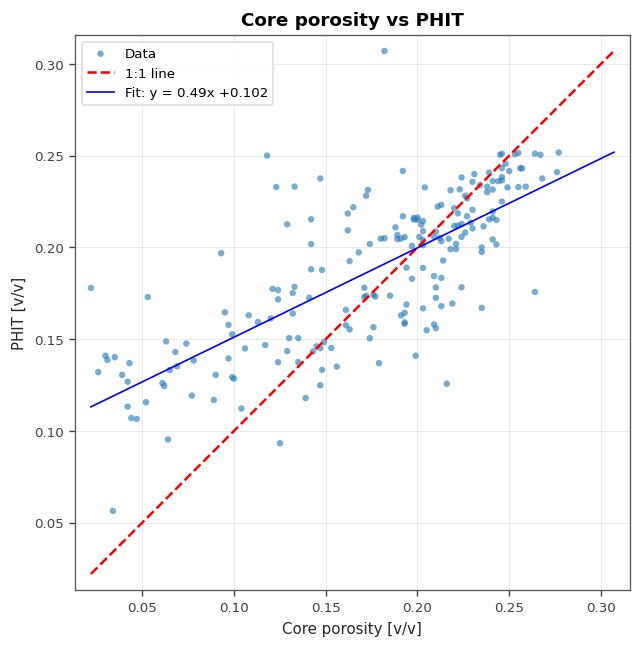

In [50]:
pp.calibration_plot(calibrate_porosity(result, core, log_curve="PHIT"), title="Core porosity vs PHIT");

A **poro-perm transform** fitted to the plugs predicts permeability from
porosity; `pp.crossplot(core, "PHIC", "KH_CORE")` draws the plugs with the fitted line.

PoroPermTransform(log10(K) = 21.72*PHI + (-2.54), R²=0.777, n=198)

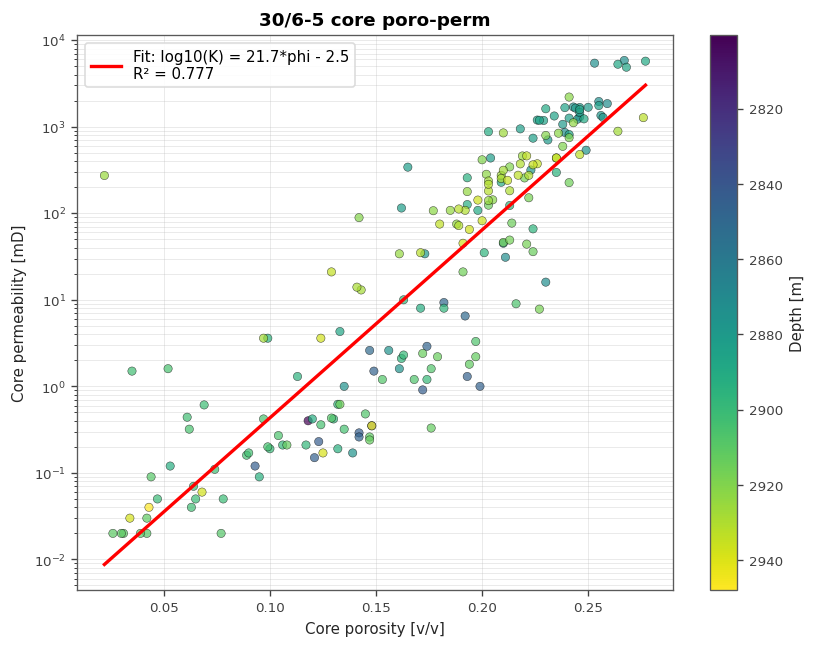

In [51]:
from petrophys.interpretation.core_analysis import fit_poro_perm
transform = fit_poro_perm(core)
pp.crossplot(core, "PHIC", "KH_CORE", transform=transform, title="30/6-5 core poro-perm")
transform

The plugs follow log10(k) = 21.7 phi - 2.54 with R² 0.78 over 198 plugs: a
tenfold increase in permeability for every 0.046 of porosity. The transform is
only supported inside the porosity range and the interval of the plugs
(2800-2948 m); applied to the soft shallow section it would predict absurd
permeabilities.

**Grain density.** Density porosity with a fixed 2.65 g/cm3 matrix is biased
where the real grain density differs. `correct_porosity_with_grain_density`
recomputes it with the measured grain density at the plug depths, interpolated
between them, as the curve `PHID_CORE`.

In [52]:
from petrophys.interpretation.core_analysis import correct_porosity_with_grain_density

correct_porosity_with_grain_density(result.well, core)
pd.Series({curve: calibrate_porosity(result, core, log_curve=curve) for curve in ["PHID", "PHID_CORE"]})

PHID              CalibrationResult(Porosity (PHID): n=200, R^2=0.645, bias=-0.0198, RMSE=0.0461, log = 0.860*core + 0.0045)
PHID_CORE    CalibrationResult(Porosity (PHID_CORE): n=200, R^2=0.537, bias=-0.0063, RMSE=0.0472, log = 0.741*core + 0.0388)
dtype: object

The measured grain density moves the bias from -0.020 to -0.006, but the
scatter does not improve (R² falls from 0.65 to 0.54): grain density is only
known at the plugs and is interpolated in between, so it adds noise of its
own. A bias fix is still worth having, because a bias shifts every volume
computed from the porosity.

**Archie's m from core.** Where a plug has both porosity and a Dean-Stark water
saturation, Archie's equation can be solved for m, given Rw, a, n and the deep
resistivity at that depth. Rw is taken at the temperature of the cored
interval, the median of the workflow's `RW` curve there.

In [53]:
from petrophys.interpretation.core_analysis import archie_m

rw_cored = result.statistics(curves=["RW"], top=core.top, bottom=core.bottom).loc["RW", "median"]
m_core = archie_m(result.well, core, rw=rw_cored, a=0.8, n=2)
rw_cored, m_core["n_points"], m_core["m_median"], m_core["m_std"]

(np.float64(0.07238073532706638), 66, 1.6621296752227024, 0.6649037153554217)

At the cored interval's Rw of 0.072 ohm.m, 66 plugs give a median m of 1.66
with a standard deviation of 0.66: a wide spread around a value below the
assumed 2. Dean-Stark saturations on conventional core are altered by filtrate
invasion and by gas expansion as the core is brought up, so an m derived from
them is a check on the assumed value, not a replacement for special core
analysis (resistivity-index and formation-factor measurements).

Core points plotted on the log tracks show the match depth by depth.

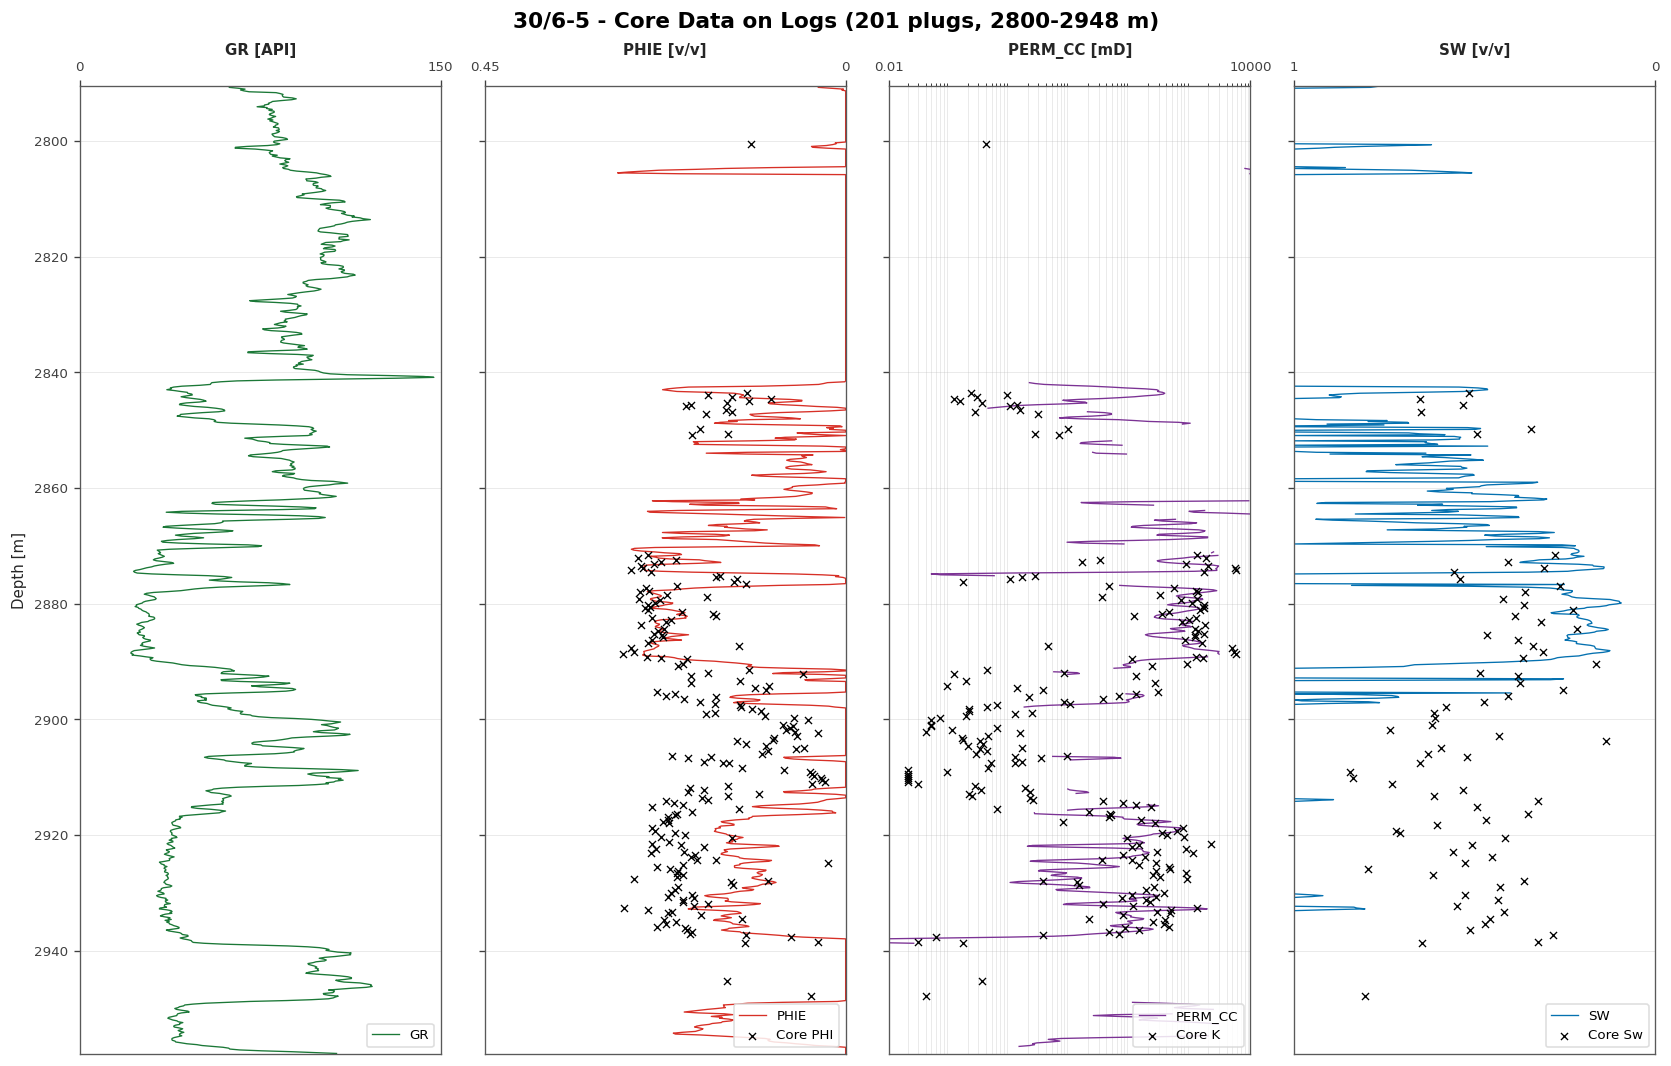

In [54]:
pp.core_on_logs(result, core, curves=["GR", "PHIE", "PERM_CC", "SW"],
                top=core.top - 10, bottom=core.bottom + 10, figsize=(14, 9));

**A second cored well: 25/5-1.** Its core calibrates much worse at face value.
A common cause is a depth mismatch: plug depths are driller's depths, logs are
logger's depths, and the two can differ by metres. `find_core_depth_shift`
scores the core-log correlation at each candidate shift, and
`shift_core_depths` applies the best one. (In practice each core run is
shifted on its own; a single bulk shift is a first look.)

In [55]:
from petrophys.interpretation.core_analysis import find_core_depth_shift, shift_core_depths

well_25 = results["25/5-1 Froey"].well            # interpreted in section 12
core_25 = core_data(well_25)
shift = find_core_depth_shift(well_25, core_25, log_curve="PHIE", max_shift=6, step=0.5)
shift

CoreDepthShift(porosity vs PHIE: shift +3.00 m, r = 0.629 (unshifted 0.430), n = 331, searched -6.00 to +6.00 m)

In [56]:
pd.Series({"as recorded": calibrate_porosity(well_25, core_25),
           "shifted": calibrate_porosity(well_25, shift_core_depths(core_25, shift))})

as recorded     CalibrationResult(Porosity (PHIE): n=331, R^2=0.185, bias=-0.0381, RMSE=0.0940, log = 0.607*core + 0.0247)
shifted        CalibrationResult(Porosity (PHIE): n=331, R^2=0.396, bias=-0.0353, RMSE=0.0808, log = 0.908*core + -0.0207)
dtype: object

The correlation peaks at a shift of +3.0 m (r 0.63 against 0.43 unshifted),
and the shifted plugs raise R² from 0.19 to 0.40 and lower the RMSE from 0.094
to 0.081. A clear peak like that is good evidence of a depth offset; apply the
shift to the core (and document it) before any calibration. Even after the
shift the match is weaker than in 30/6-5, so the remaining scatter needs a
closer look per core run.

---
## 17. Sensitivity analysis: cutoffs and parameters

How much does the answer depend on our choices? Two views:

1. **Cutoffs.** `cutoff_sensitivity` recomputes the net-pay flags on the
   interpreted curves for a grid of cutoffs and returns one row per
   combination. The curves do not change, only the flags, so this is fast. The
   pivot gives Brent Group net pay (m) for each VCL and Sw cutoff.
2. **Parameters.** `parameter_sensitivity` re-runs an evaluation with each
   setting moved to a low and a high value, one at a time, and returns the
   data of a tornado chart.

In [57]:
from petrophys.evaluation import cutoff_sensitivity, parameter_sensitivity

grid = cutoff_sensitivity(result.well, vcl_cutoffs=[0.2, 0.3, 0.4, 0.5], phie_cutoffs=0.10,
                          sw_cutoffs=[0.4, 0.5, 0.6, 0.7, 0.8], **BRENT)
grid.pivot(index="vcl_cutoff", columns="sw_cutoff", values="net_pay_thickness").round(1)

sw_cutoff,0.4,0.5,0.6,0.7,0.8
vcl_cutoff,,,,,
0.2,18.4,20.0,21.3,22.9,23.9
0.3,18.4,20.3,22.1,24.5,26.2
0.4,18.4,20.4,22.6,25.1,27.1
0.5,18.4,20.4,22.7,25.3,27.3


Read the table along its axes. With the VCL cutoff at 0.40, the Sw cutoff
moves Brent Group net pay from 18.4 m (Sw < 0.4) to 27.1 m (Sw < 0.8); with
the Sw cutoff at 0.6, the VCL cutoff moves it only from 21.3 to 22.7 m,
because most of the Brent Group pay is clean sand that passes any reasonable
clay cutoff.

For the parameters, the evaluation is a full re-interpretation:
`brent_pay` runs `pp.interpret` with some settings changed and returns the
Brent Group net pay. Each case costs two interpretations of the whole well.

,case,low,high,swing
0,m 1.8 / 2.2,25.60,20.27,5.33
1,Sw cutoff 0.50 / 0.70,20.27,24.54,4.27
2,Rw 0.05 / 0.09 ohm.m (at 230 degF),24.69,21.03,3.66
3,n 1.8 / 2.2,23.01,21.95,1.06
4,PHIE cutoff 0.12 / 0.08,22.40,22.40,0.00


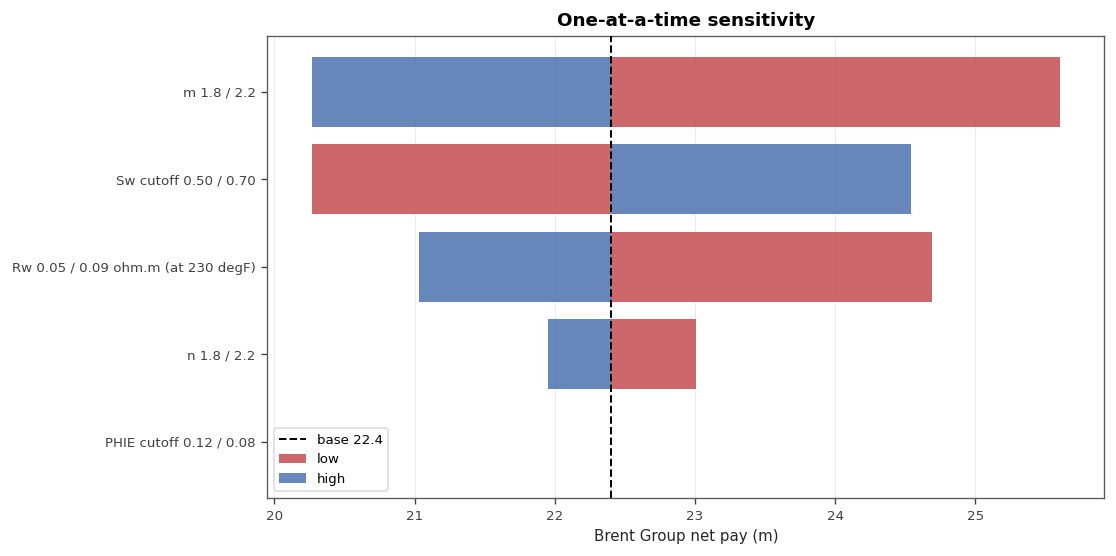

In [58]:
def brent_pay(**changes):
    return pp.interpret(well, **{**SETTINGS, **changes}).summary(**BRENT)["net_thickness"]["net_pay"]


tornado = parameter_sensitivity(brent_pay, {
    "Rw 0.05 / 0.09 ohm.m (at 230 degF)": ({"rw": 0.05}, {"rw": 0.09}),
    "m 1.8 / 2.2": ({"m": 1.8}, {"m": 2.2}),
    "n 1.8 / 2.2": ({"n": 1.8}, {"n": 2.2}),
    "Sw cutoff 0.50 / 0.70": ({"sw_cutoff": 0.50}, {"sw_cutoff": 0.70}),
    "PHIE cutoff 0.12 / 0.08": ({"phie_cutoff": 0.12}, {"phie_cutoff": 0.08}),
})
pp.tornado_plot(tornado["case"], tornado["low"], tornado["high"], base=tornado.attrs["base"]["value"],
                xlabel="Brent Group net pay (m)", title="One-at-a-time sensitivity");
tornado[["case", "low", "high", "swing"]].round(2)

`low` is the net pay at the first setting in the label and `high` at the
second; `swing` is the gap between them, and the rows are ranked by it. Around
the 22.4 m base case, m swings net pay by about 5 m, the Sw cutoff and Rw by
about 4 m each, n by about 1 m, and the porosity cutoff not at all (the pay sands
are far above 0.12 porosity). The ranking is the useful output: it tells you
where to spend effort (a water sample, special core analysis) before quoting
net pay.

---
## 18. Specialist data

The library covers more than the log interpretation. Each of these is one call
on a bundled data set; the linked lesson goes deeper.

**Gap filling with machine learning** (lesson 13). The neutron log of COSTA
well HW-27 has a gap: 273 of its 409 samples hold values. `pp.impute` trains a
gradient-boosted model on the other logs of the other COSTA wells, which share
its Kharaib carbonate, and fills the gap (it leaves HW-27 itself out of the training wells); the result is added as
`NPHI_IMPUTED`, measured values where they exist and predictions in the gap.
It needs the `ml` extra.

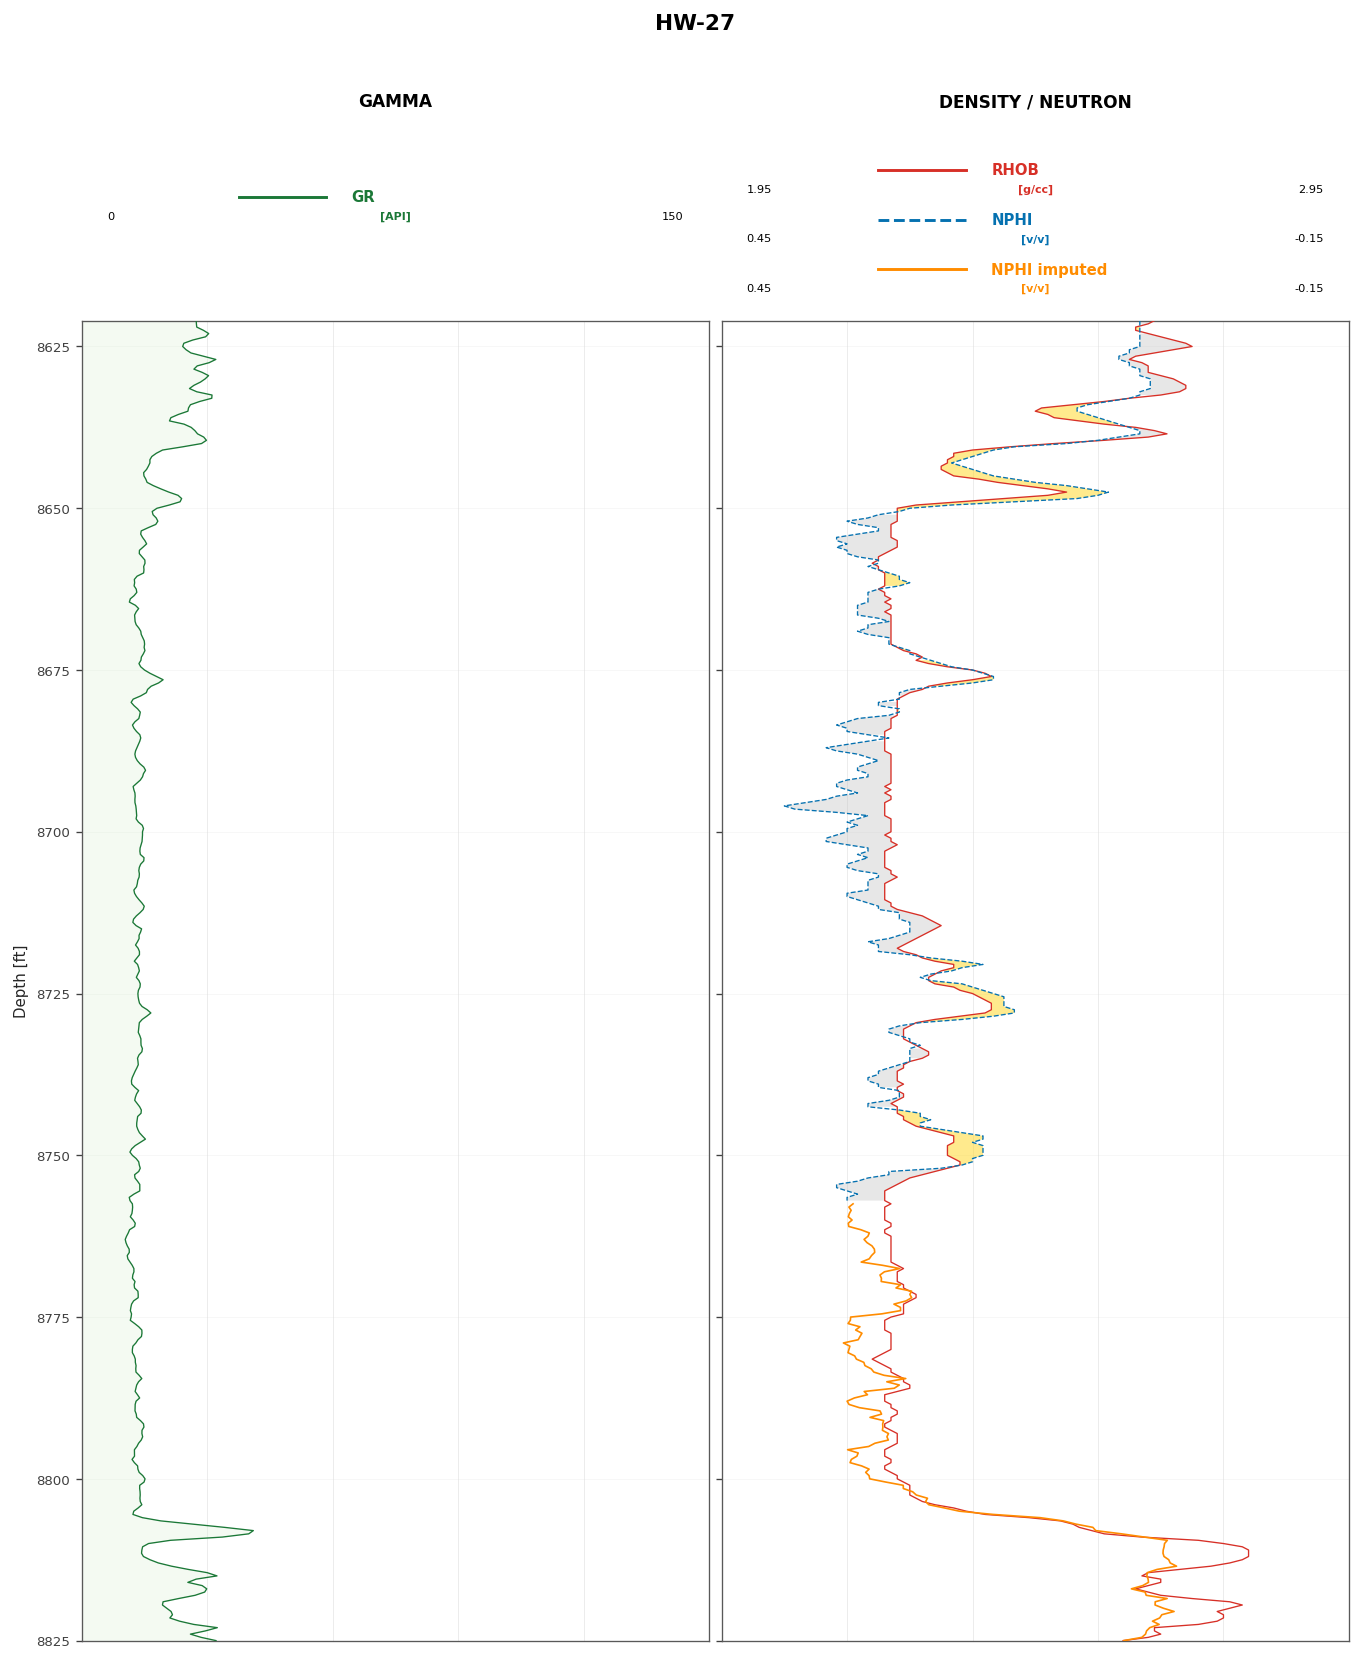

In [59]:
filled = pp.impute(pp.sample("HW-27"), "NPHI", train_wells=[pp.sample(name) for name in pp.list_samples("costa")])
pp.plot(filled, curves=["GR", "RHOB", "NPHI_IMPUTED", "NPHI"],
        curve_styles={"NPHI_IMPUTED": {"color": "darkorange", "line_style": "-"}}).show()

The gap is the bottom 67.5 ft of the well (8757.5-8825 ft). The measured
neutron is drawn over the filled curve, so the orange line shows only the
prediction in the gap, where it follows the density: porous limestone down to
about 8800 ft, then the dense base. The model learns from the other wells, so
check a filled curve against what the geology allows before using it.

**NMR** (lesson 14). `NMRData.from_las` reads processed NMR logs; here the
Daydream-1 CMR, whose total porosity is `TCMR` and free fluid `CMFF`. It
derives bound fluid, the T2 cutoff and Timur-Coates permeability.

In [60]:
from petrophys.interpretation.nmr import NMRData

nmr = NMRData.from_las(pp.sample("daydream1_cmr"), mphi_mnemonic="TCMR", mffi_mnemonic="CMFF")
nmr

NMRData(samples=15606, depth=3755.0-4145.1, MFFI, MBVI, stored perm, schlumberger_cmr, cutoff=33.0ms)

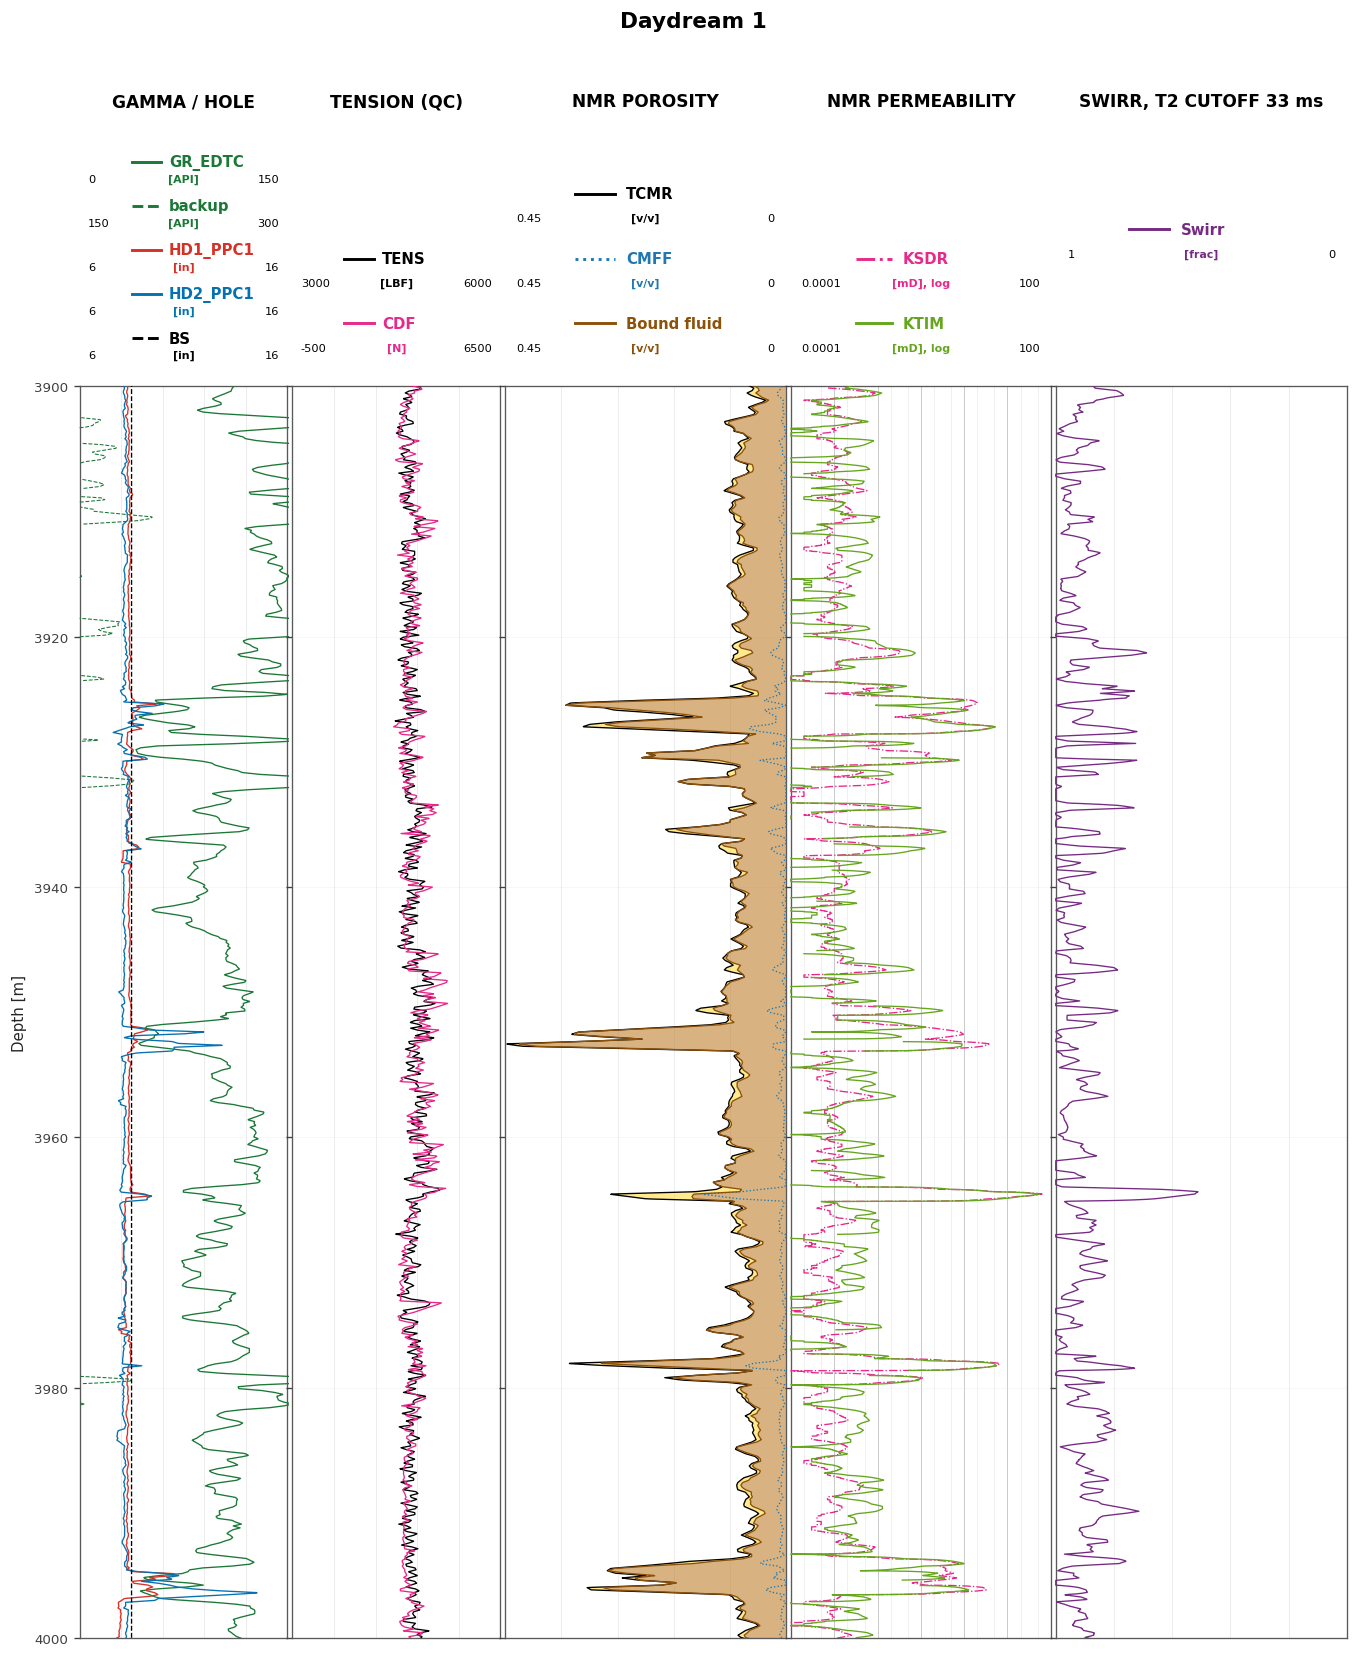

In [61]:
pp.nmr_panel(pp.read(pp.sample("daydream1_cmr")), top=3900, bottom=4000);

In this interval the CMR reads a total porosity of mostly 0.05-0.09 with
almost no free fluid, and the vendor's Timur-Coates and SDR permeabilities
stay far below 1 mD, a tight section. The tallest porosity spikes (about 3925, 3952 and 3994-3996 m)
are bound fluid, with almost no free fluid, where the caliper opens to 10-14.5 in on an
8.5 in bit: enlarged hole, not porous rock; the one near 3978 m, in gauge hole, is also
mostly bound fluid. Only thin streaks near 3964 m and 3978 m
show porosity, free fluid and permeability rising together (`KTIM` about 50 and 6 mD).

**Spectral gamma** (lesson 12, part 3). `interpret_spectral_gamma` reads the
thorium and uranium curves of 25/5-1, adds the uranium share of the gamma ray
and flags the uranium-dominated samples, typical of organic-rich shale.

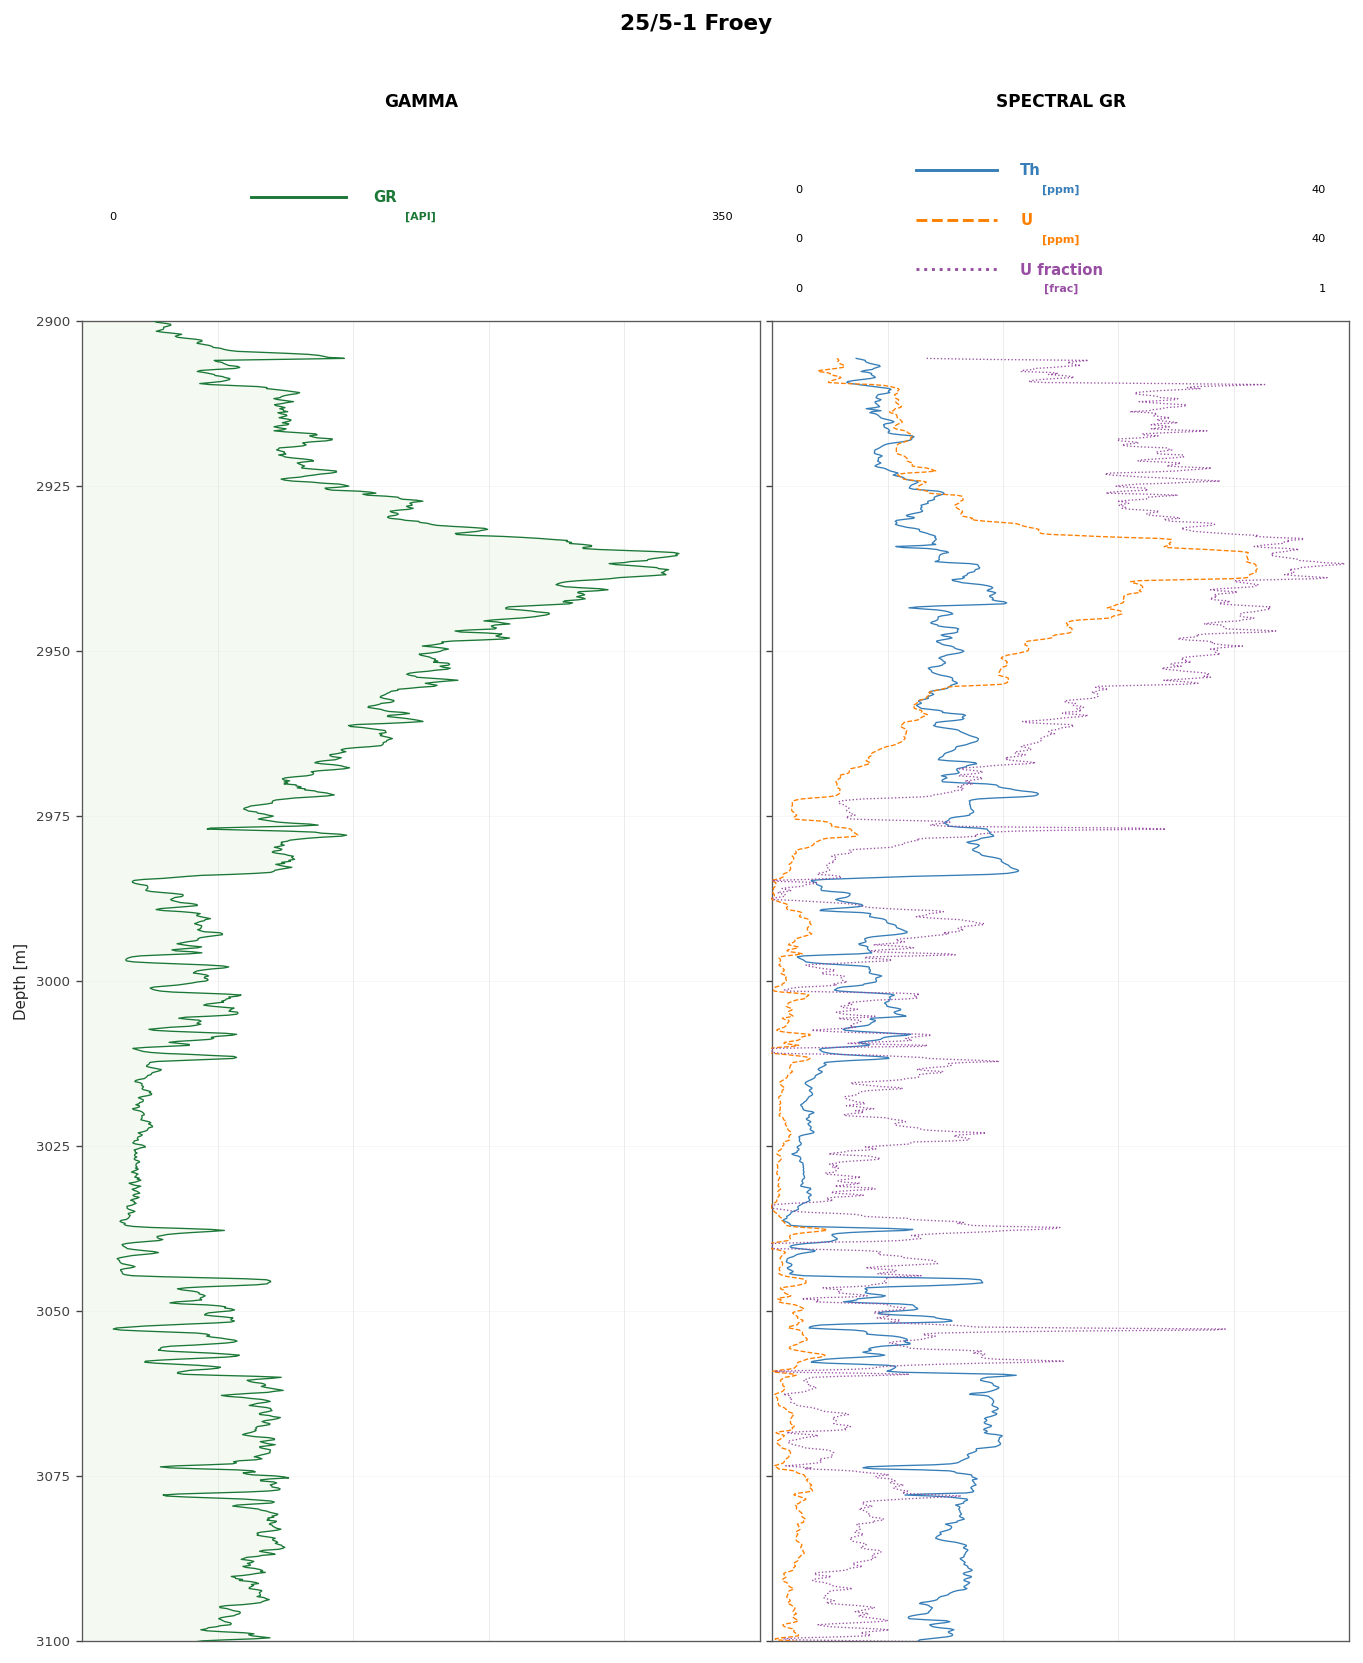

In [62]:
from petrophys.interpretation.geochemistry import interpret_spectral_gamma

gamma_well = pp.read(pp.sample("25_5-1"))
interpret_spectral_gamma(gamma_well, alias_overrides={"SGR": ["GR"]})
pp.plot(gamma_well, curves=["GR", "THORIUM", "URANIUM", "SGR_URANIUM_FRACTION"], top=2900, bottom=3100,
        curve_styles={"GR": {"right": 350}, "THORIUM": {"left": 0, "right": 40}, "URANIUM": {"left": 0, "right": 40},
                      "SGR_URANIUM_FRACTION": {"left": 0, "right": 1}}).show()

The hot shale at 2905-2965 m reads up to about 34 ppm uranium, which carries
60-80 % of its gamma ray (`SGR_URANIUM_FRACTION`): the signature of
organic-rich shale, whose high GR is not clay. The shale below 3060 m is
thorium-rich (12-15 ppm) with little uranium, ordinary clay-rich shale. A
gamma-ray clay volume would call both shales equally clayey; the spectral
curves tell them apart.

**Zonation** (statistical layering). `zone_well` splits a log into zones of
similar character by change-point detection, a quick first layering before
the geological picks.

In [63]:
from petrophys.evaluation.zonation import zone_well

zone_well(result.well, ["GR"], min_thickness=5, **BRENT).to_dataframe()

,zone,top,bottom,thickness,samples,GR_mean
0,1,2841.01929,2848.79175,7.92481,52,52.227269
1,2,2848.94409,2857.02148,8.22974,54,86.270222
2,3,2857.17383,2862.05054,5.02906,33,95.429061
3,4,2862.20312,2867.68945,5.63868,37,65.112568
4,5,2867.84180,2872.87109,5.18164,34,41.977647
5,6,2873.02344,2877.90039,5.02930,33,47.469727
6,7,2878.05273,2890.70190,12.80152,84,27.721921
7,8,2890.85425,2899.54102,8.83912,58,65.109484
8,9,2899.69360,2904.57031,5.02906,33,94.823343
9,10,2904.72266,2911.58081,7.01050,46,86.161537


With a minimum thickness of 5 m, the Brent Group GR splits into 16 zones; the
clean upper Etive sand (mean GR 28 API, 2878-2891 m) stands out as one zone,
the reservoir picked from the GR alone.

**Saturation-height** (lesson 15). In a hydrocarbon column, Sw falls with
height above the free-water level (FWL) as capillary pressure rises.
`fit_j_function_from_well` turns height into the Leverett J-function with each
sample's porosity and permeability and fits Sw = a J^b. COSTA well HW-3
(Kharaib-2) has no FWL pick, so we **assume** one 1 ft below its deepest valid
sample, at 7991 ft. The function also takes depth as true vertical depth (the
warning says so), which holds for a vertical well.

JFunctionModel(Sw = 0.0680 * J^-0.2321, R2=0.282, n=313)

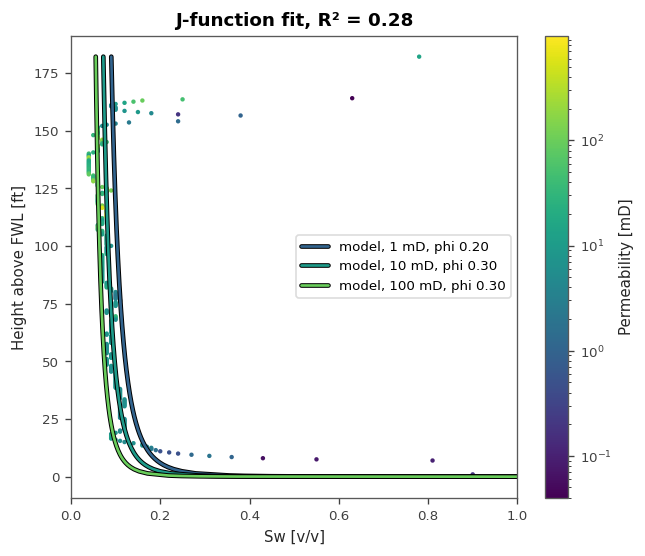

In [64]:
from petrophys.interpretation.saturation.height import fit_j_function_from_well

j_model = fit_j_function_from_well(pp.read(pp.sample("HW-3")), fwl_depth=7991, sw_curve="SW_INPUT",
                                   perm_curve="PERM_CC", phi_curve="PHIE_CC")
j_model.plot();
j_model

The fit, Sw = 0.068 J^-0.232 over 313 samples, has an R² of only 0.28: the
model follows the low, nearly constant Sw high in the column but not the
scatter of the transition zone in the bottom 25 ft, where the assumed FWL
matters most. The model curves keep the expected order: at the same height,
tighter rock holds more water.

Two more parts of the library need inputs that the tour does not have room
for: **borehole images** from DLIS arrays, which need a 112 MB file (lesson 16),
and **custom workflows** built from the library's steps and your own
(lesson 21).
The **MCP server** `petrophys-mcp` lets an LLM run these same calls
(lesson 20).

---
## 19. Visualization gallery

`pp.plot` covers most log displays: `template=` picks a layout (`"auto"`,
`"raw"`, `"petrophysics"`, `"minerals"`, `"comprehensive"`), `tracks=`
chooses tracks, `curves=` chooses curves, and `curve_styles=` changes colour,
scale or fill of any curve. `petrophys.visualization` adds the crossplots and
specialist charts; they take a well or an interpretation result.

### 19a. Templates and styles

The `"minerals"` template shows the mineral volumes of the solver next to
porosity and saturation.

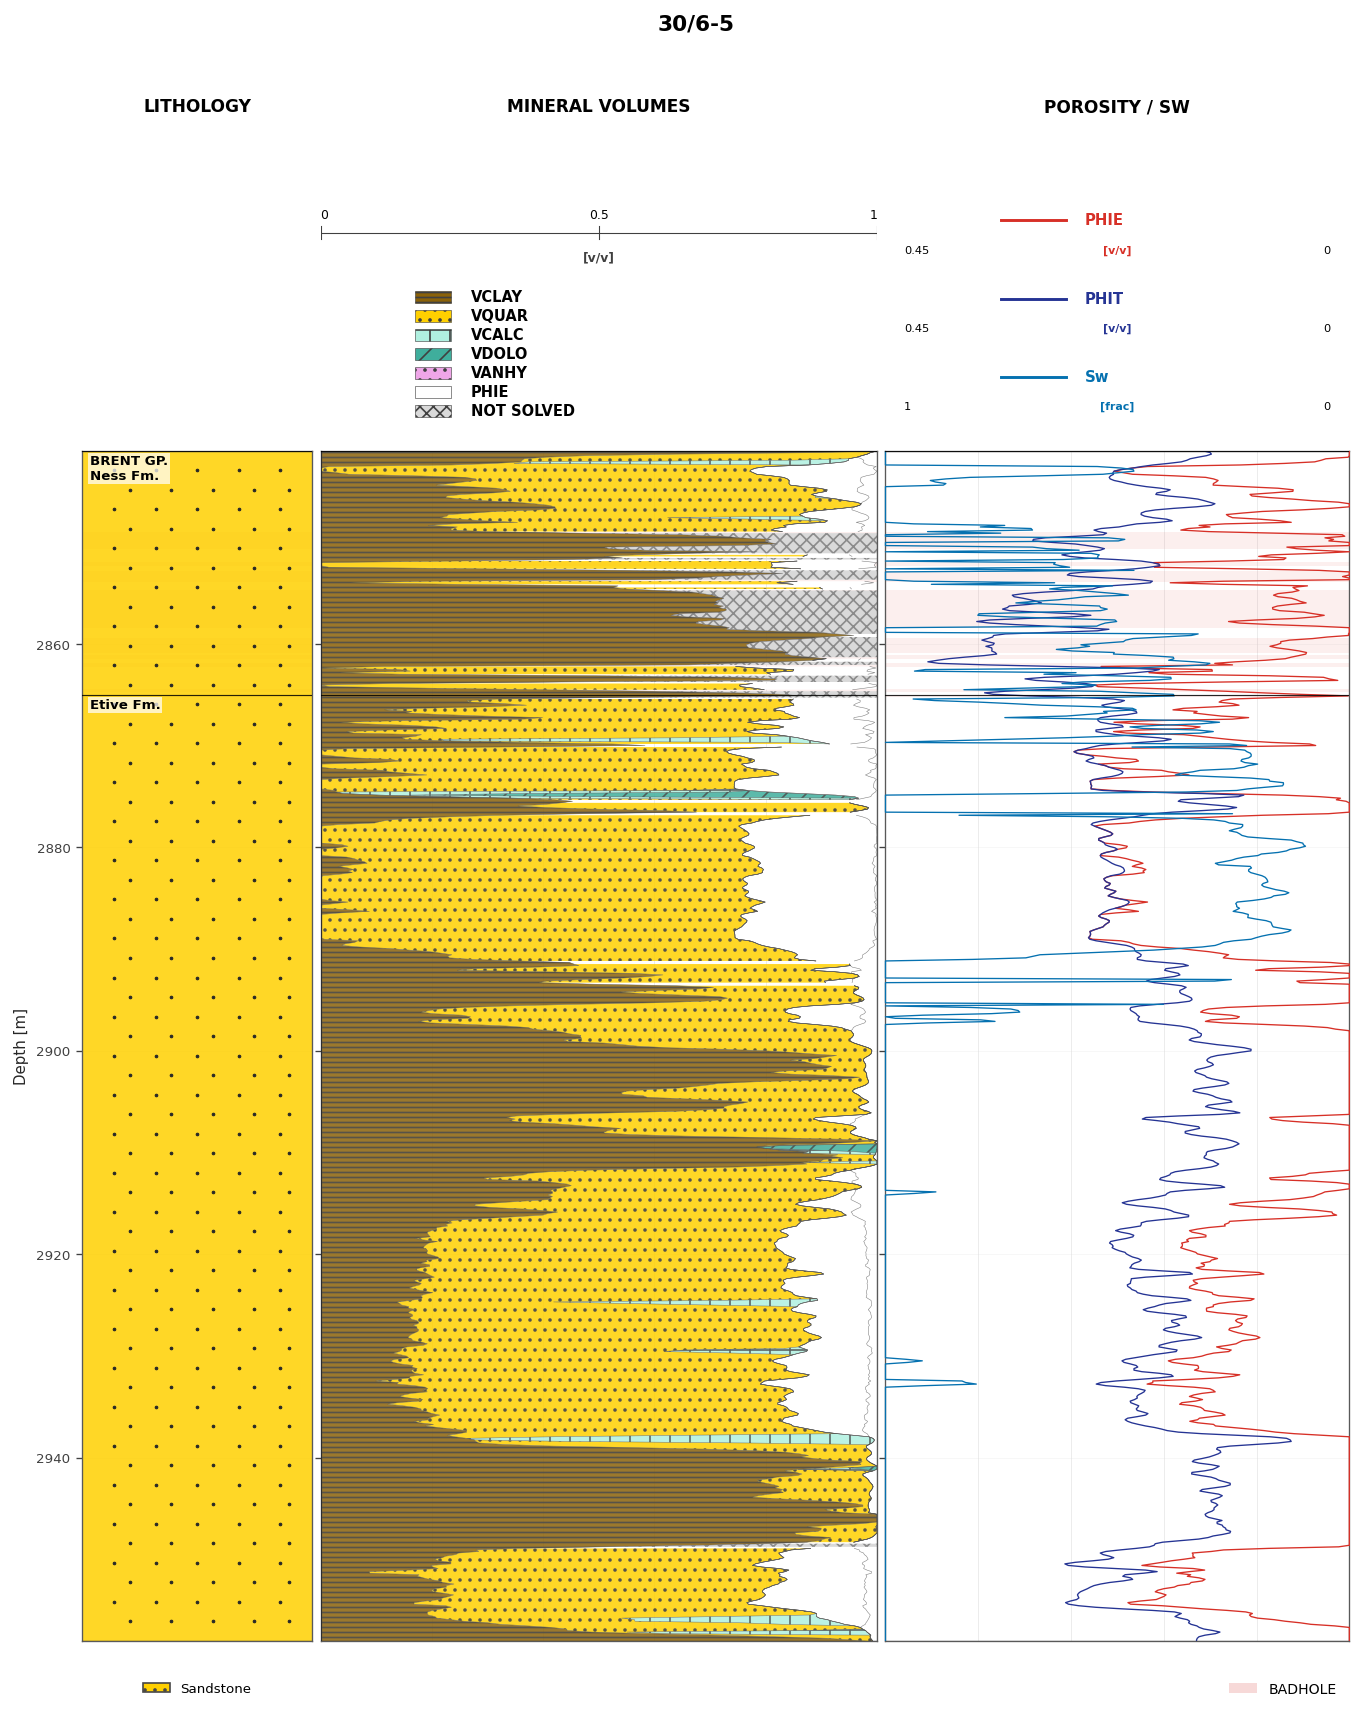

In [65]:
pp.plot(result, template="minerals", **BRENT).show()

`curve_styles` restyles chosen curves: here GR in black on a 0-200 API scale
with a fill, and the deep resistivity drawn thicker.

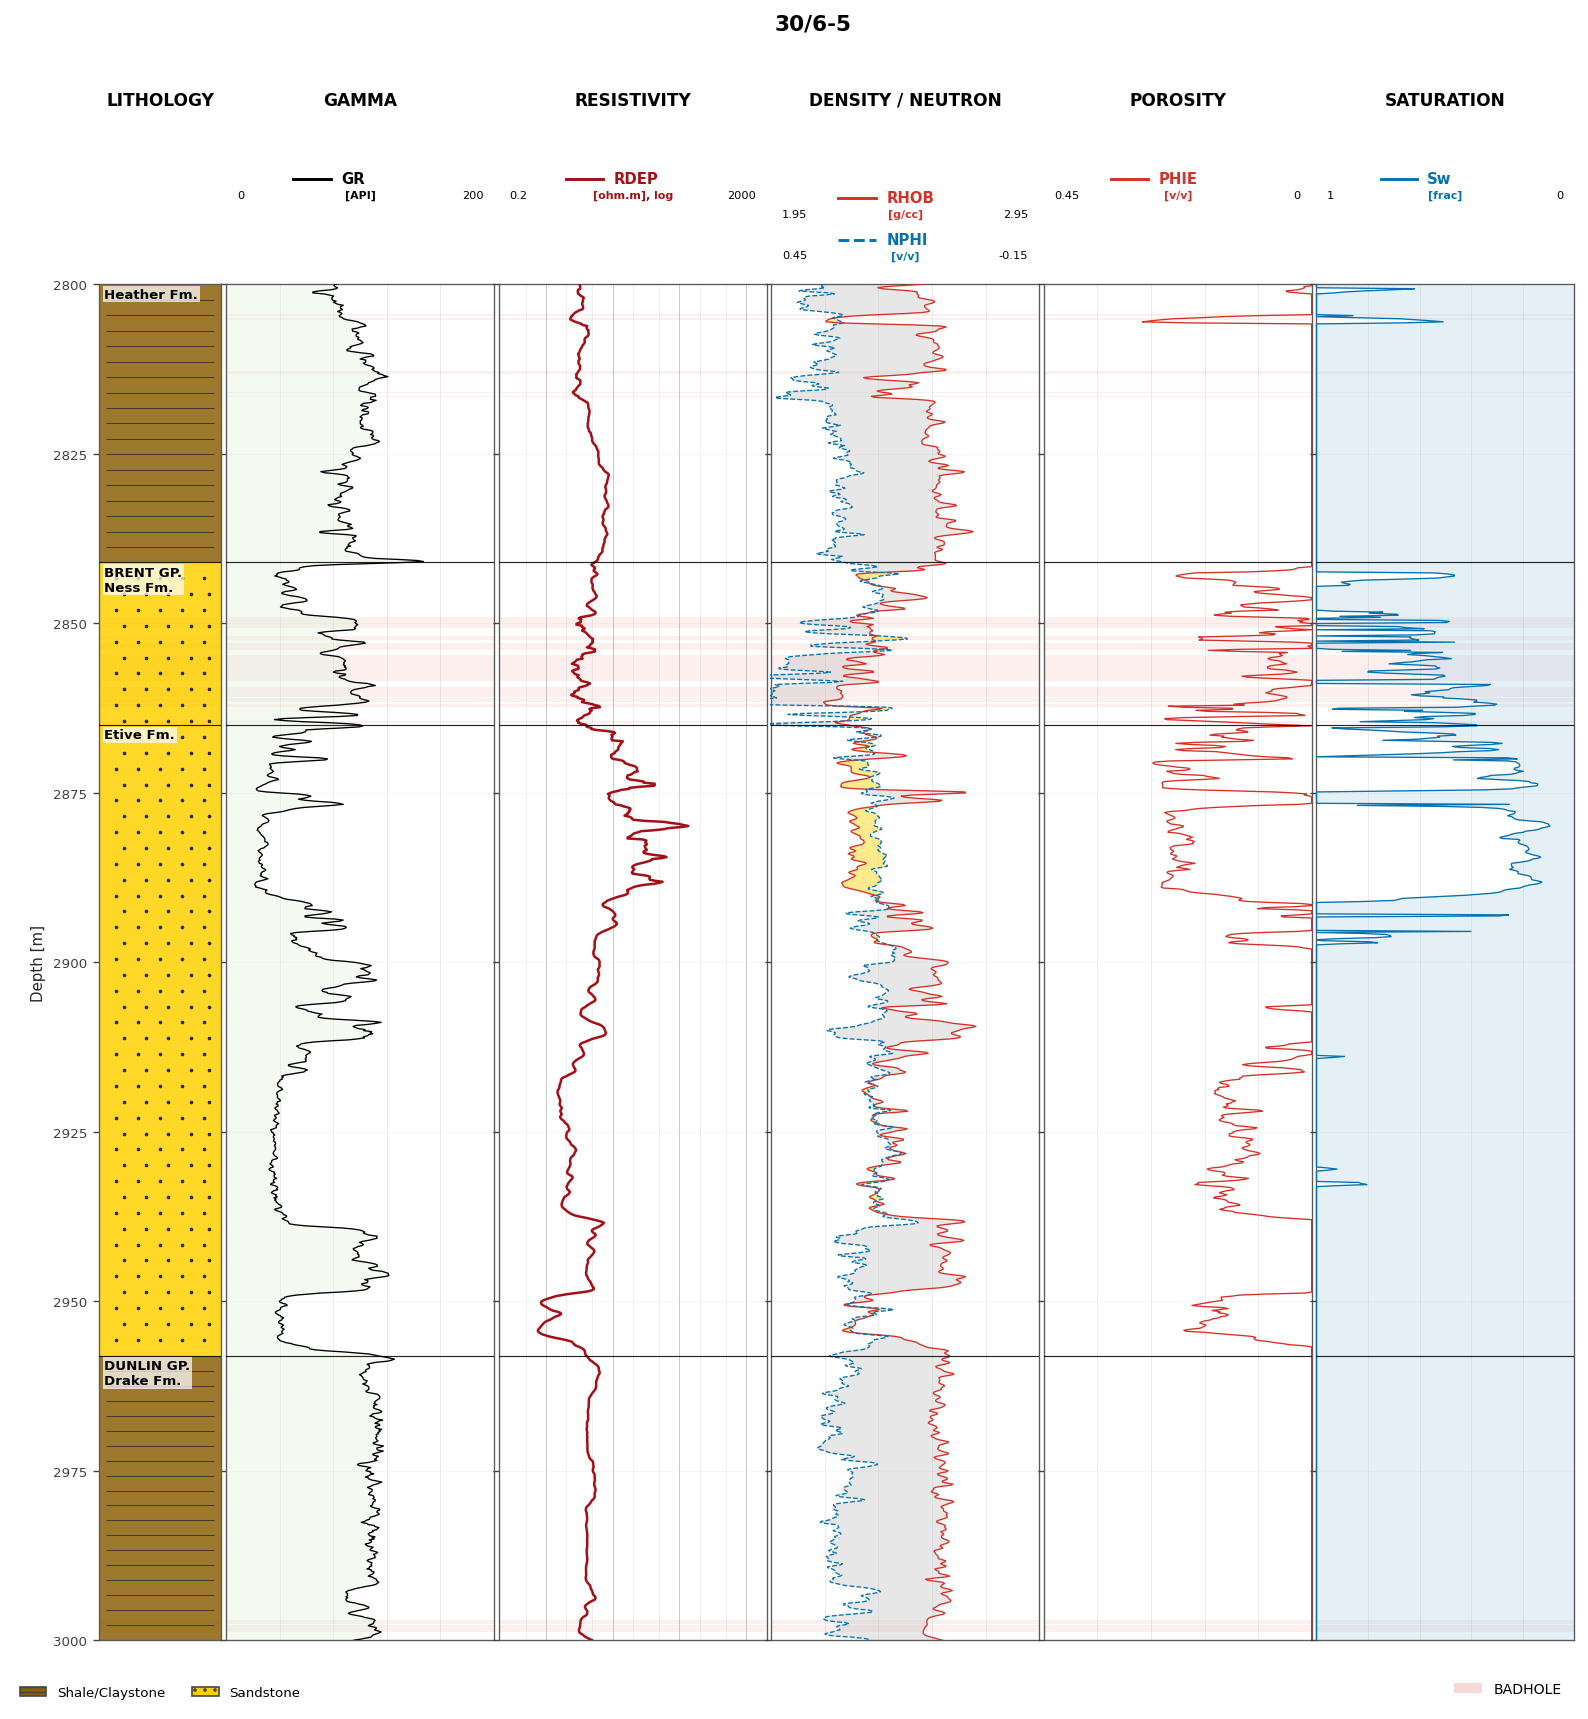

In [66]:
pp.plot(result, curves=["GR", "RDEP", "RHOB", "NPHI", "PHIE", "SW"], top=2800, bottom=3000,
        curve_styles={"GR": {"color": "black", "right": 200, "fill": "left"},
                      "RDEP": {"line_width": 1.5}}).show()

### 19b. Triple combo

The first plot most petrophysicists look at: GR and caliper, resistivity, and
density-neutron. `triple_combo` draws it for any depth window.

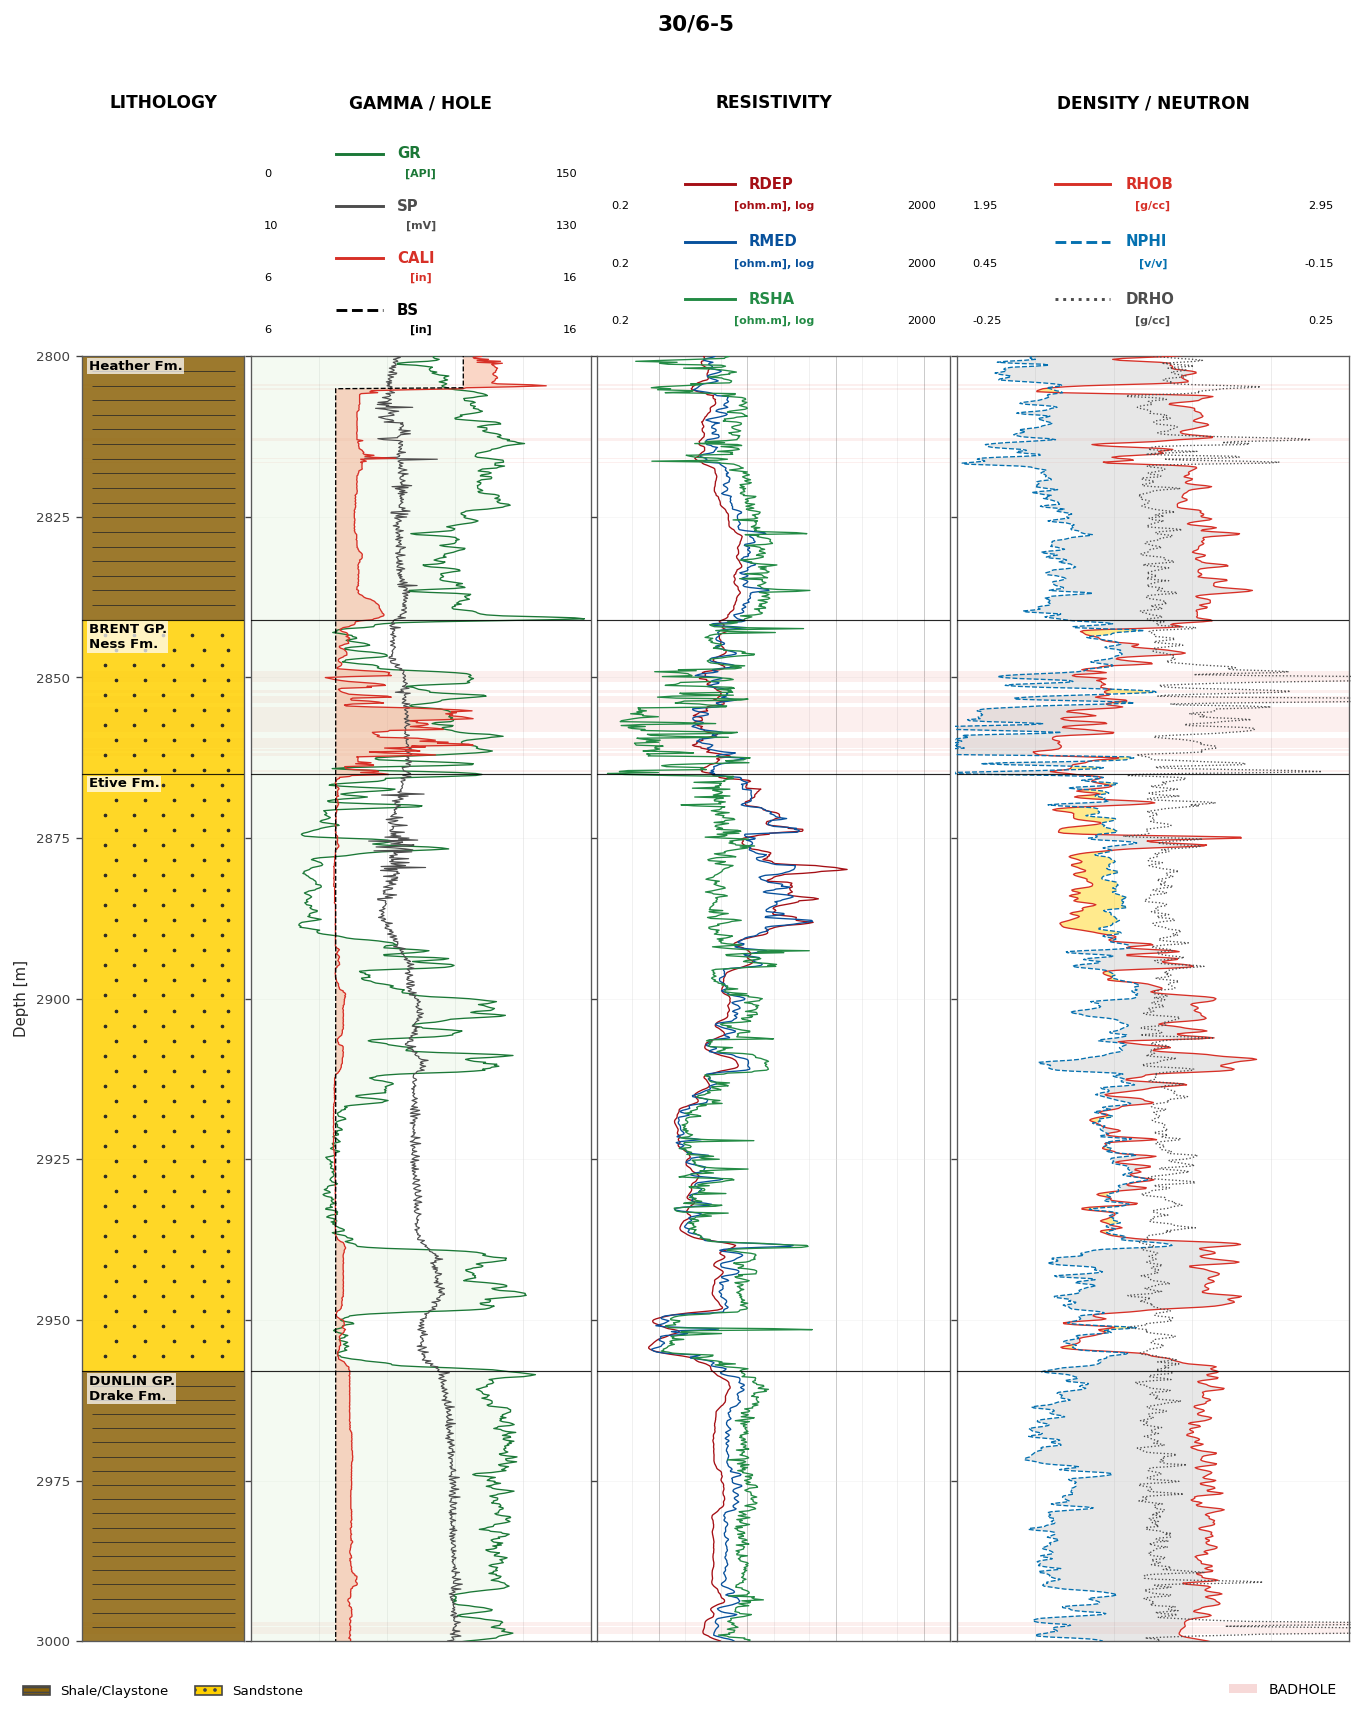

In [67]:
pp.triple_combo(result, top=2800, bottom=3000).show()

### 19c. Crossplots

A density-neutron crossplot separates lithologies: points fall along lines
from the matrix points (sandstone, limestone, dolomite) towards the fluid
point. `pp.crossplot(result, "NPHI", "RHOB")` draws the matrix lines, porosity ticked 0-40 %.

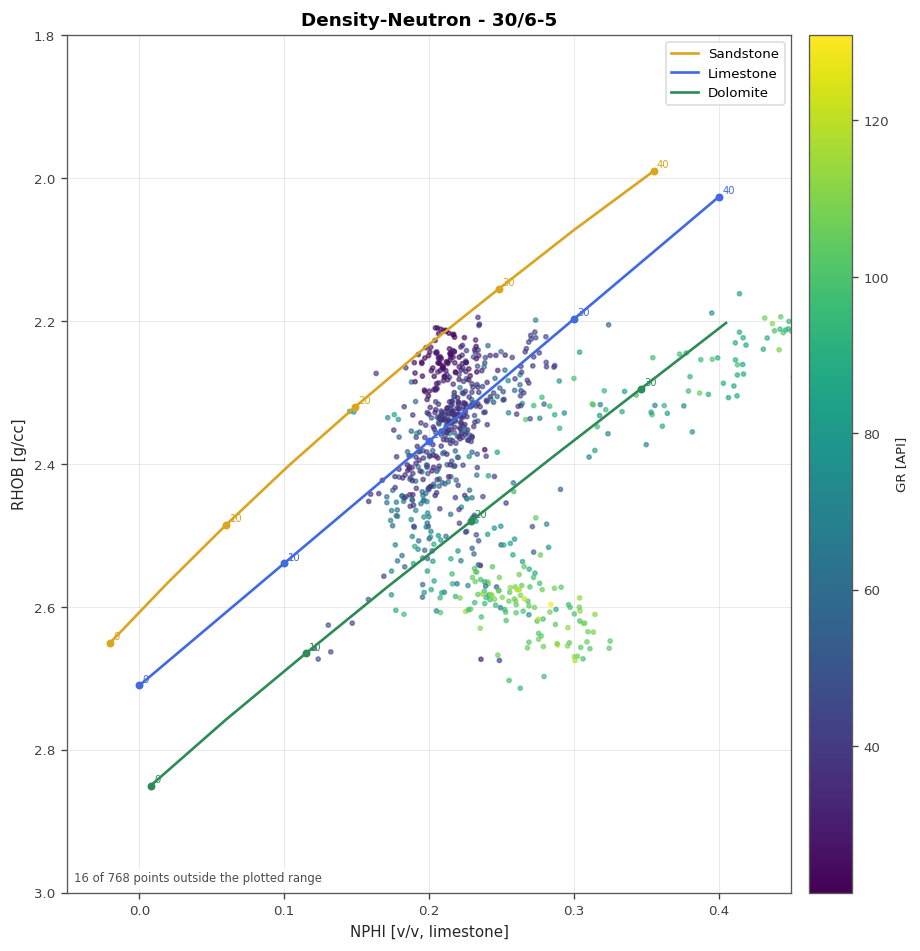

In [68]:
pp.crossplot(result, "NPHI", "RHOB", top=2841, bottom=2958)

The lines are the chartbook's (Schlumberger Por-11, fresh water; the neutron is
limestone-calibrated). The clean, oil-bearing upper Etive sand plots between the sandstone
and limestone lines at 20-25 % porosity; the water-bearing lower Etive plots further right,
mostly right of the limestone line, as hydrocarbon lowers both readings and moves points
up and to the left. The shalier, high-GR samples move to higher neutron and density, down
and to the right.

Any other pair is drawn as points, coloured by `color=`; `chart="plain"` draws a pair that has a chart
of its own (porosity and Sw: Buckles) as points too.

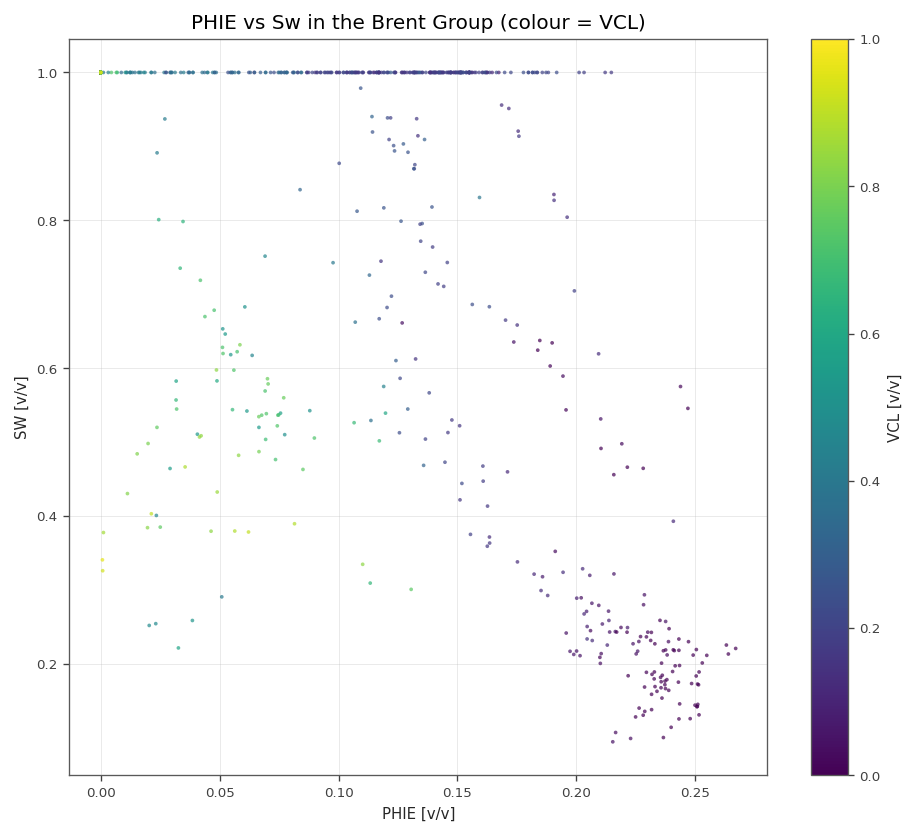

In [69]:
pp.crossplot(result, "PHIE", "SW", color="VCL", chart="plain", top=2841, bottom=2958,
             title="PHIE vs Sw in the Brent Group (colour = VCL)").show()

### 19d. Pickett plot

On log-log axes of Rt against PHIE, Archie's equation becomes straight lines of
constant Sw with slope -m. Water-bearing clean rock should plot along the
Sw = 100 % line, which checks Rw and m together. We use the water-bearing
Statfjord Group sand (3223-3556 m). The plot takes the Rw at its temperature, the
median of the workflow's `RW` curve over the plotted points, and plots clean rock
only (`VCL` up to 0.15).

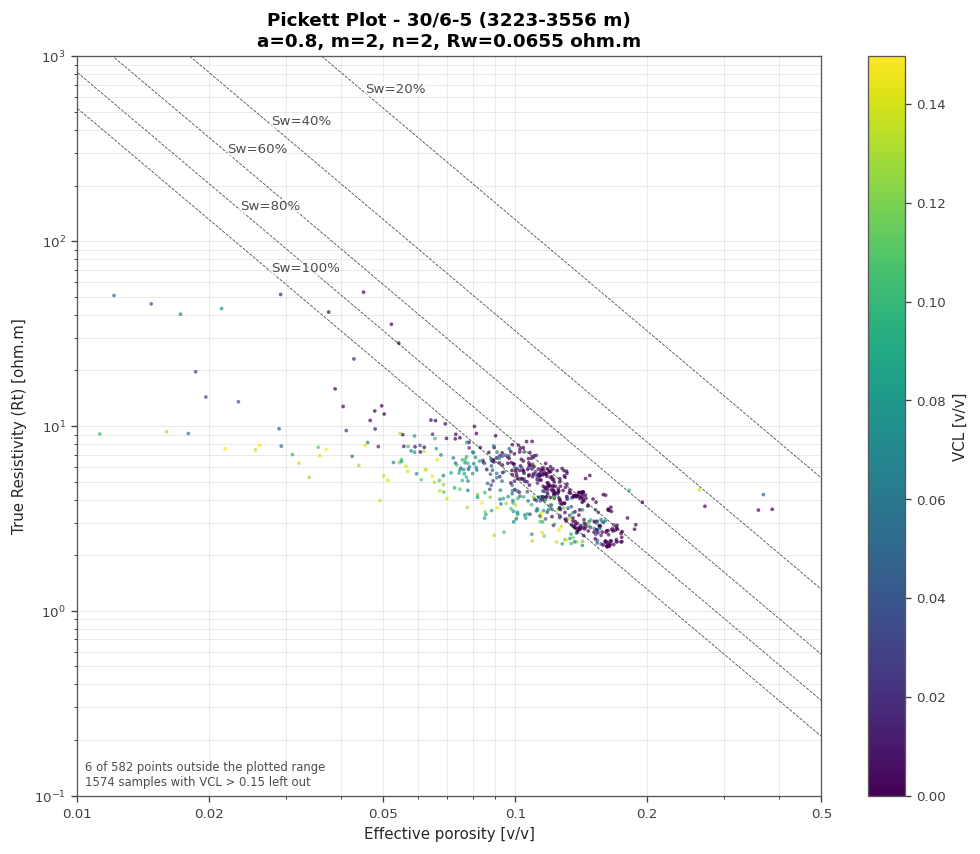

In [70]:
pp.crossplot(result, "PHIE", "RDEP", top=3223, bottom=3556, a=0.8, m=2, n=2)

At the Statfjord temperature Rw is 0.0655 ohm.m. The clean, porous points
(PHIE 0.1-0.2) fall mostly between the 80 % and 100 % lines, close to water
bearing, which supports the Rw and m we use; the note counts the shaly samples left
out, which would plot to the left at low PHIE, where Archie does not apply.

### 19e. Zone flags

`zone_flags_plot` draws the net-flag curves as coloured columns, a compact
summary of where each cutoff passes.

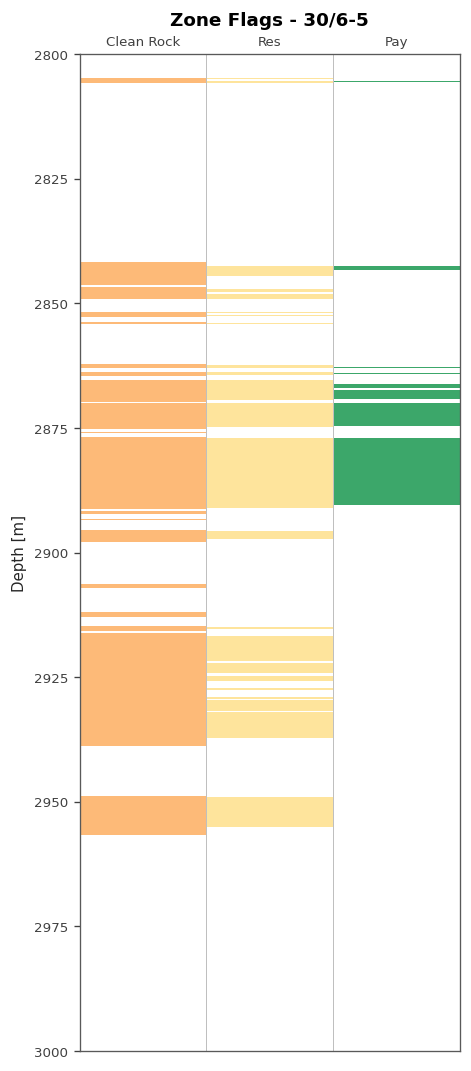

In [71]:
pp.zone_flags_plot(result, ["NET_ROCK", "NET_RES", "NET_PAY"], top=2800, bottom=3000, figsize=(4, 9));

---
## Pitfalls

- **Rw needs its temperature.** Pass `rw_meas_temp` with every `rw`; without
  it the value is taken at the median formation temperature and saturation
  shifts strongly.
- **Whole-well totals are not reservoir numbers.** Shallow unconsolidated
  sediment can pass net-pay cutoffs, the more so because one Rw serves the whole
  well while shallow formation water is usually fresher. Report a reservoir
  window (`summary(top=, bottom=)`) or formation rows you can justify
  geologically, or give shallow zones their own Rw (`zones=`, lesson 10).
- **Mixed-rank tops overlap.** Choose one rank (`formation_summary(rank=...)`)
  before adding rows; never sum a group and its formations.
- **Gamma-ray endpoints are a choice.** `gr_min` and `gr_max` are used as
  given; endpoints picked automatically from the log are bounded to at most
  20 API clean and at least 100 API shale.
- **One bad clay indicator spoils a minimum.** VCL is the lowest of the GR and
  neutron-density estimates; check each one in known shales and sands
  (`curves=["VCL_GR", "VCL_ND"]`). The SP joins only when you set both SP
  baselines (`sp_min`, `sp_max`) for an SP without baseline drift.
- **Calibrate against core, but check core depths first.** A metre-scale core
  depth offset (25/5-1) degrades every calibration statistic;
  `find_core_depth_shift` finds it.
- **Empirical permeability can be biased by an order of magnitude.** Prefer a
  core-calibrated transform where core exists, and do not apply it far outside
  the porosity range and interval of the plugs.
- **Shaly-sand models can have no solution in shale.** Where the shale term
  exceeds the measured conductivity, some models return NaN (the model does
  not apply there). Average Sw over reservoir-quality rock, not over a whole
  interval.
- **Core saturation units.** `SWC`/`SOC` in 30/6-5 are percent labelled `frac`;
  the library infers the percent scale, converts them to v/v and warns.
- **`inplace=True` changes the well you pass;** the default does not.

## Recap

- `pp.read` loads a well (with optional tops and lithology), `pp.interpret` runs
  the full interpretation on a copy, and `pp.plot` draws it.
- Every choice is a setting of `pp.interpret`; change one and compare the
  results to see what a method does.
- `result.warnings`, `result.print_trace()` and `result.to_dataframe()` say
  what the interpretation did and assumed.
- `result.summary(top=, bottom=)`, `result.formation_summary()` and
  `result.zone_summary()` turn curves into reservoir numbers; choose one rank
  and a reservoir window.
- Several wells go through the same calls; core calibration
  (`core_data`, `calibrate_porosity`) measures log bias, after a
  depth match; `cutoff_sensitivity` and `parameter_sensitivity` show which
  inputs control the answer.

## Exercises

1. Interpret 30/6-5 with `sw_model="archie"` and `sw_model="indonesia"`. Which
   formations gain or lose pay in `formation_summary()`?
2. Set `gr_min` and `gr_max` to the 5th and 95th GR percentiles of the
   Heather-to-TD section only. How do VCL and Brent Group net pay respond?
3. Shift the 25/5-1 core by the best shift of section 16 and fit its
   poro-perm transform. Compare it with the 30/6-5 transform.
4. Add `bht` (a temperature of your choice) for 16/7-1 in section 12 and see
   how its Rw and net pay change. What would you need to replace the
   assumption?

## What's next

Work through the lessons in the table at the top for depth on any section,
starting with [lesson 10](part_b_advanced/10_dynamic_workflow_glass_box.ipynb)
for the workflow and [lesson 11](part_b_advanced/11_formation_and_interval_analysis.ipynb)
for formation reporting. To run the same steps on your own LAS file, tops and
core data, continue with [Your own data](../docs/own_data.md).

---
## API quick reference

The functions used in this tour. The cell after the table imports every name
listed, so the table cannot drift from the library.

**Front door** (`import petrophys as pp`)

| Name | Purpose |
|---|---|
| `pp.read(path, formations=, lithology=)` | Read LAS/DLIS/CSV/TSV into a `Well`; a list or folder reads several |
| `pp.interpret(well, **settings)` | Full interpretation on a copy; several wells give one result per well |
| `pp.plot(well_or_result, top=, bottom=, template=, tracks=, curves=)` | Multi-track log plot; several wells with `curves=` in one figure |
| `pp.DynamicWorkflowConfig` | The interpretation settings, each documented |
| `pp.read_formations(source, well=)` | Formation tops as a validated table |
| `pp.impute(well, curve, train_wells=)` | Fill a missing curve with a trained model |
| `pp.export_context(result, path)` | JSON summary of an interpreted well for an LLM |
| `pp.sample(name)`, `pp.list_samples()` | Paths of bundled sample data |

**The result** of `pp.interpret`

| Name | Purpose |
|---|---|
| `result.well`, `result.status`, `result.warnings` | Interpreted well, status and warnings |
| `result.summary(top=, bottom=)` | Net thickness and property statistics, whole well or window |
| `result.formation_summary(rank=)`, `result.zone_summary(zones)` | Per-formation and per-zone tables |
| `result.print_trace()`, `result.to_dataframe()`, `result.step(name)` | The step-by-step trace; one step's record |
| `result.statistics(curves=, top=, bottom=)` | Curve statistics over a window |
| `result.to_las(path)`, `result.to_json(path)` | Exports |
| `results.summary()`, `results["name"]` | Several wells: one row per well; one well's result |

**Library functions** (`petrophys.preprocessing`, `petrophys.interpretation`, `petrophys.evaluation`, `petrophys.visualization`)

| Name | Purpose |
|---|---|
| `preprocessing.CurveStandardizer().report(well)` | Preview mnemonic and unit standardization |
| `preprocessing.detect_washout(well)` | Bad-hole flags and statistics |
| `interpretation.core_analysis.core_data(well)` | Core plugs stored as curves, as `CoreData` |
| `interpretation.core_analysis.calibrate_porosity`, `calibrate_permeability` | Log-core comparison statistics |
| `interpretation.core_analysis.fit_poro_perm(core)` | Core poro-perm transform |
| `interpretation.core_analysis.correct_porosity_with_grain_density` | Density porosity with measured grain density |
| `interpretation.core_analysis.archie_m` | m from core Sw |
| `interpretation.core_analysis.find_core_depth_shift`, `shift_core_depths` | Core-to-log depth match |
| `interpretation.nmr.NMRData.from_las(path)` | Processed NMR logs |
| `interpretation.geochemistry.interpret_spectral_gamma(well)` | Thorium, uranium and potassium interpretation |
| `interpretation.saturation.height.fit_j_function_from_well(well, fwl_depth=)` | J-function saturation-height model |
| `evaluation.calculate_flow_units(core)` | Hydraulic flow units from FZI |
| `evaluation.summaries.ooip` | In-place volume from net pay, porosity and Sw |
| `evaluation.cutoff_sensitivity`, `parameter_sensitivity` | Net pay over a cutoff grid; tornado data |
| `evaluation.zonation.zone_well(well, curves)` | Change-point zonation |
| `pp.crossplot(data, x, y)` | Any two curves, with the chart their pair calls for: neutron-density, Pickett, Buckles, flow units, core poro-perm, ... |
| `pp.pickett_plot`, `pp.nd_plot`, `pp.buckles_plot`, `pp.flow_unit_plot`, `pp.poro_perm_plot`, ... | The same charts by name, with their usual curves as defaults |
| `pp.triple_combo`, `pp.zone_flags_plot`, `pp.tornado_plot` | Quick-look log display, net flags and sensitivity charts |
| `pp.calibration_plot`, `pp.core_on_logs` | Core calibration plots |

In [72]:
import importlib

REFERENCE = {
    "petrophys": ["read", "interpret", "plot", "DynamicWorkflowConfig", "read_formations", "impute",
                  "export_context", "sample", "list_samples", "crossplot", "pickett_plot", "nd_plot",
                  "buckles_plot", "flow_unit_plot", "poro_perm_plot", "triple_combo",
                  "zone_flags_plot", "tornado_plot", "calibration_plot", "core_on_logs"],
    "petrophys.preprocessing": ["CurveStandardizer", "detect_washout"],
    "petrophys.interpretation.core_analysis": [
        "core_data", "calibrate_porosity", "calibrate_permeability", "fit_poro_perm",
        "correct_porosity_with_grain_density", "archie_m", "find_core_depth_shift",
        "shift_core_depths"],
    "petrophys.interpretation.nmr": ["NMRData"],
    "petrophys.interpretation.geochemistry": ["interpret_spectral_gamma"],
    "petrophys.interpretation.saturation.height": ["fit_j_function_from_well"],
    "petrophys.evaluation": ["calculate_flow_units", "cutoff_sensitivity", "parameter_sensitivity"],
    "petrophys.evaluation.summaries": ["ooip"],
    "petrophys.evaluation.zonation": ["zone_well"],
}
missing = [f"{module}.{name}" for module, names in REFERENCE.items()
           for name in names if not hasattr(importlib.import_module(module), name)]
assert not missing, missing
print(f"All {sum(len(v) for v in REFERENCE.values())} names in the quick reference resolve.")

All 38 names in the quick reference resolve.
